# Lung Cancer Classification: Proposed Swin Transformer + Loss-Function Experiments

**Framework:** TensorFlow / Keras  |  **Platform:** Google Colab (GPU runtime recommended)

This notebook is an *experiment bench*. You change values in **one configuration cell (Section 3)**, run the notebook top to bottom, and every run is appended to a CSV log so you can compare configurations later.

> **Educational / research use only.** This is not a medical diagnostic tool.

## Objective

Investigate whether a **modified ("proposed") Swin Transformer** and/or a different **loss function** (categorical cross-entropy, sparse categorical cross-entropy, label smoothing, focal loss) changes classification accuracy and macro-F1 on the lung-cancer image dataset.

## Three honest points before you start

1. **A different loss function does not automatically improve accuracy.** Cross-entropy is already the standard loss for classification. Label smoothing or focal loss *can* help (for example with over-confident predictions or class imbalance) but they can also make no difference or make results worse. This notebook is set up so you can *measure* the effect instead of assuming it.
2. **"Proposed" means "modified by you", not "proven better".** The architecture in this notebook is a compact Keras re-implementation of the published Swin Transformer design (Liu et al., 2021). Nothing here is novel or validated until *your* experiments show it, ideally over several random seeds.
3. **Pretrained CNNs vs. Swin trained from scratch is not an equal comparison.** The four CNNs use ImageNet-pretrained weights, while the Swin models here start from random weights (no pretrained Swin is available in plain Keras). Expect the pretrained CNNs to be strong. The cleanest comparison is **SwinBaseline vs. the proposed Swin** (same code, same training recipe, only your change differs).

## Models available in this notebook

| Name in `MODEL_NAMES` | What it is |
|---|---|
| `ResNet50`, `EfficientNetB0`, `MobileNetV2`, `DenseNet121` | ImageNet-pretrained CNN backbones + your classification head (transfer learning) |
| `SwinBaseline` | **Original-style Swin-Tiny hyperparameters** in this notebook's Keras implementation. This is your reference. Do not edit it. |
| `SwinTransformer` | **Your proposed / modified Swin.** Controlled by `SWIN_CONFIG` (and the shared head / loss settings). |

## Notebook sections

1. Project overview (this cell)
2. Google Colab environment setup
3. Centralized configuration
4. Dataset path and structure inspection
5. Dataset loading and preprocessing
6. Data visualization and class distribution
7. Model architecture implementation (Swin from scratch in Keras)
8. Loss function and optimizer configuration
9. Model building and summary
10. Model training
11. Model evaluation
12. Performance visualization
13. Experiment comparison (CSV log)
14. Save results and final models
15. Future experimentation guide (including how to do a fair baseline-vs-proposed comparison)

## 2. Google Colab Environment Setup

This section:

1. Checks that the needed libraries exist (installs only what is missing; never upgrades TensorFlow, which could break Colab).
2. Imports everything once.
3. Mounts Google Drive.
4. Verifies TensorFlow and the GPU.

**Recommended runtime:** *Runtime → Change runtime type → GPU (T4 or better).*

In [1]:
# Check that the libraries we need are installed. Colab already includes most of them.
# We only install what is missing and we never upgrade TensorFlow.
import importlib.util, subprocess, sys

REQUIRED_PACKAGES = {      # import name -> pip name
    "tensorflow": "tensorflow",
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
}

missing = [pip for mod, pip in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Done. If TensorFlow was just installed, use Runtime -> Restart session, then run again from the top.")
else:
    print("All required libraries are already installed. Nothing to install.")
    print("(No extra Swin library is needed: the Swin Transformer is implemented in Section 7.)")

All required libraries are already installed. Nothing to install.
(No extra Swin library is needed: the Swin Transformer is implemented in Section 7.)


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # must be set BEFORE importing Keras

import gc, json, time, random, hashlib, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
import sklearn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
)
from IPython.display import display

print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("Keras       :", tf.keras.__version__)
print("NumPy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.13.16
TensorFlow  : 2.21.0
Keras       : 3.13.2
NumPy       : 2.4.6
scikit-learn: 1.6.1


In [3]:
# Mount Google Drive (only works inside Colab).
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running inside Google Colab, so Drive is not mounted.")
    print("Make sure the paths in the configuration cell exist on this machine.")

Mounted at /content/drive


In [4]:
# Verify the GPU. Training a Swin Transformer on a CPU would be extremely slow.
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("GPU(s) found:", [g.name for g in gpus])
    for g in gpus:
        # Allocate GPU memory gradually instead of all at once.
        tf.config.experimental.set_memory_growth(g, True)
else:
    print("WARNING: no GPU found. In Colab use Runtime -> Change runtime type -> GPU.")
    print("You can continue, but training will be very slow.")

GPU(s) found: ['/physical_device:GPU:0']


## 3. Centralized Configuration

**This is the only cell you normally need to edit.** Everything below it reads these values.

Suggested alternatives are written as comments next to each parameter.

**Fair-comparison rule of thumb:** when you compare two runs, change **one** thing between them (for example only the loss, or only the window size). See Section 15.

In [5]:
# =====================================================================
#  CENTRALIZED CONFIGURATION  -  edit values in THIS cell only
# =====================================================================

# ---------------------------------------------------------------------
# A. Experiment label (saved in the CSV log so you can tell runs apart)
# ---------------------------------------------------------------------
EXPERIMENT_NAME  = "swin_ce_run1"   # e.g. "swin_ce", "swin_label_smoothing_0.1", "swin_window4"
EXPERIMENT_NOTES = ""               # free text, e.g. "testing drop_path=0.2"

# ---------------------------------------------------------------------
# B. Paths (Google Drive)
# ---------------------------------------------------------------------
DATASET_ROOT    = "/content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V4"
MODELS_DIR      = "/content/drive/MyDrive/Lung_Cancer_Trained_Models"
CHECKPOINTS_DIR = "/content/drive/MyDrive/Lung_Cancer_Checkpoints"
RESULTS_DIR     = "/content/drive/MyDrive/Lung_Cancer_Experiment_Results"   # graphs, metrics, CSV log

# The notebook looks for these sub-folder names inside DATASET_ROOT (case-insensitive).
# If your folders have other names, add them to the lists.
SPLIT_FOLDER_NAMES = {
    "train": ["train", "training"],
    "val":   ["valid", "val", "validation"],
    "test":  ["test", "testing"],
}

# ---------------------------------------------------------------------
# C. Model selection (train one or several, one after the other)
# ---------------------------------------------------------------------
MODEL_NAMES = [
    # "ResNet50",
    # "EfficientNetB0",
    # "MobileNetV2",
    # "DenseNet121",
    "SwinBaseline",       # original-style Swin-Tiny (reference for a fair baseline-vs-proposed comparison)
    "SwinTransformer",    # YOUR proposed / modified Swin (controlled by SWIN_CONFIG below)
]
# Examples:
# MODEL_NAMES = ["SwinTransformer"]
# MODEL_NAMES = ["SwinBaseline", "SwinTransformer"]      # cleanest baseline-vs-proposed comparison
# MODEL_NAMES = ["ResNet50", "SwinTransformer"]

# ---------------------------------------------------------------------
# D. Training parameters (shared by ALL models, so the comparison is fair)
# ---------------------------------------------------------------------
IMAGE_SIZE = (224, 224)
# Swin needs: IMAGE_SIZE / patch_size to be divisible by window_size (224/4 = 56, 56/7 = 8 -> OK).
# Other valid combinations: (224,224) with window 7 | (256,256) with window 8 | (112,112) with window 7.

BATCH_SIZE = 16
# Suggested: 8, 16, 32, 64. If you see an out-of-memory error, lower it (Swin uses a lot of memory).

EPOCHS = 10
# Maximum number of epochs. EarlyStopping usually stops sooner.

LEARNING_RATE = 1e-3
# Suggested values to experiment with: 1e-3, 5e-4, 1e-4, 5e-5, 1e-5

OPTIMIZER_NAME = "adam"
# Options: "adam", "adamw", "sgd", "rmsprop"
# Default "adam" with WEIGHT_DECAY = 0.0 keeps the same setup as a plain Adam baseline.
# "adamw" is the usual choice for transformers.

WEIGHT_DECAY = 0.0
# Suggested: 0.0, 1e-4, 1e-2, 5e-2 (the last two are typical for AdamW on transformers).
# Applies decoupled weight decay (shrinks weights a little every step to reduce overfitting).

SGD_MOMENTUM = 0.9          # only used when OPTIMIZER_NAME = "sgd"

SEED = 42
# Controls weight initialisation, dropout, shuffling. For serious results repeat the SAME
# experiment with several seeds (for example 42, 43, 44, 45, 46) and report mean +/- std.

EARLY_STOPPING_PATIENCE = 3     # stop after this many epochs without validation-loss improvement
REDUCE_LR_PATIENCE      = 3     # lower the learning rate after this many epochs without improvement
REDUCE_LR_FACTOR        = 0.5   # new_lr = old_lr * factor
MIN_LEARNING_RATE       = 1e-7  # never go below this

# ---------------------------------------------------------------------
# E. Data options
# ---------------------------------------------------------------------
USE_AUGMENTATION = False
# False: use the images exactly as stored (recommended if your dataset is already augmented).
# True : light random flip/rotation/zoom on the TRAINING data only (never on validation/test).

AUGMENTATION_CONFIG = {
    "flip": "horizontal",       # "horizontal", "vertical", "horizontal_and_vertical"
    "rotation": 0.05,           # fraction of a full turn (0.05 = about +/-18 degrees)
    "zoom": 0.10,               # +/-10 percent
}

CHECK_DUPLICATES = False
# True: hash every image file to detect EXACT duplicates shared between train/val/test (data leakage).
# This reads every file once (can take a few minutes on Drive). Set False to skip.

USE_CLASS_WEIGHTS = True
# True: classes with fewer training images get a larger weight in the loss.
# Useful for imbalanced data, but keep it the SAME in every experiment you compare.

# ---------------------------------------------------------------------
# F. CNN transfer-learning options (ResNet50, EfficientNetB0, MobileNetV2, DenseNet121)
# ---------------------------------------------------------------------
USE_PRETRAINED  = True      # True: ImageNet weights (needs internet in Colab). False: random weights.
FREEZE_BACKBONE = True      # True: train only the new classification head (fast, usual baseline).
                            # False: fine-tune the whole network (use a smaller LEARNING_RATE, e.g. 1e-5).

# ---------------------------------------------------------------------
# G. Classification head (shared by ALL models, so only the backbone differs)
# ---------------------------------------------------------------------
HEAD_CONFIG = {
    "pooling": "max",           # "avg" (global average pooling) or "max"
    "hidden_units": [],         # [] = just pooling -> dropout -> softmax. Example: [256] or [512, 128]
    "activation": "relu",       # activation for hidden layers: "gelu", "relu", "swish"
    "dropout_rate": 0.2,        # suggested: 0.0, 0.1, 0.2, 0.3, 0.5
}

# ---------------------------------------------------------------------
# H. Loss function configuration
# ---------------------------------------------------------------------
LOSS_FUNCTION_NAME = "categorical_crossentropy"
# Options:
#   "categorical_crossentropy"                 labels are one-hot vectors, e.g. [0, 1, 0]
#   "sparse_categorical_crossentropy"          labels are integers, e.g. 1   (same maths as above, different label format)
#   "categorical_crossentropy_label_smoothing" categorical CE, requires LABEL_SMOOTHING > 0
#   "categorical_focal_crossentropy"           focal loss: down-weights easy examples (sometimes used for imbalance)

LABEL_SMOOTHING = 0.0
# Replaces the hard target [0, 1, 0] by a softer one, e.g. [0.05, 0.9, 0.05] for 0.1 and 3 classes.
# Discourages over-confident predictions. Suggested values: 0.0, 0.05, 0.1, 0.15
# Works with categorical losses only (NOT with the sparse loss).

FOCAL_GAMMA = 2.0
# Only for "categorical_focal_crossentropy". Higher = ignore easy examples more. Suggested: 1.0, 2.0, 3.0

FOCAL_ALPHA = 0.25
# Only for "categorical_focal_crossentropy". A single number scales the whole loss (Keras default 0.25).

# ---------------------------------------------------------------------
# I. Swin Transformer architecture
# ---------------------------------------------------------------------
# I-1. SwinBaseline: original-style Swin-Tiny hyperparameters. DO NOT EDIT: it is your fixed reference.
SWIN_BASELINE_CONFIG = {
    "patch_size": 4, "window_size": 7, "embed_dim": 96,
    "num_heads": [3, 6, 12, 24], "depths": [2, 2, 6, 2],
    "mlp_ratio": 4.0,
    "dropout_rate": 0.0, "attention_dropout_rate": 0.0, "drop_path_rate": 0.2,
    "qkv_bias": True, "use_shifted_window": True, "use_relative_position_bias": True,
}

# I-2. SwinTransformer: YOUR proposed / modified version. Edit freely.
SWIN_CONFIG = {
    "patch_size": 4,
    # Size of the image patches turned into tokens. Smaller = finer detail but slower. Suggested: 2, 4, 8

    "window_size": 7,
    # Attention is computed inside windows of window_size x window_size tokens. Suggested: 4, 7, 8
    # (must divide the token grid: 224/4 = 56 -> 7 is OK; 8 is also OK when IMAGE_SIZE = 256).

    "embed_dim": 96,
    # Feature size of the first stage (doubles at every later stage). Suggested: 48, 64, 96, 128
    # Must be divisible by num_heads[0] (and the doubled sizes by the later heads).

    "num_heads": [3, 6, 12, 24],
    # Attention heads per stage. Suggested: [2,4,8,16], [3,6,12,24], [4,8,16,32]

    "depths": [2, 2, 6, 2],
    # Number of Swin blocks per stage (must have the same length as num_heads).
    # Smaller models for small datasets: [2,2,2,2] or [1,1,3,1]

    "mlp_ratio": 4.0,
    # Hidden size of the MLP inside each block = mlp_ratio * dim. Suggested: 2.0, 3.0, 4.0

    "dropout_rate": 0.1,
    # Dropout after attention projection and inside the MLP. Suggested: 0.0, 0.1, 0.2

    "attention_dropout_rate": 0.0,
    # Dropout on the attention weights. Suggested: 0.0, 0.05, 0.1

    "drop_path_rate": 0.1,
    # Stochastic depth: randomly skips whole blocks while training (rate grows with depth).
    # Suggested: 0.0, 0.1, 0.2, 0.3

    "qkv_bias": True,                    # learnable bias in the query/key/value projection
    "use_shifted_window": True,          # False = plain window attention only (ablation: removes the "Shifted" part)
    "use_relative_position_bias": True,  # False = no learned relative position bias in attention (ablation)
}

# ---------------------------------------------------------------------
# J. Misc
# ---------------------------------------------------------------------
RUN_SELF_TESTS    = True    # quick tests of the Swin code (a few seconds). Keep True.
SHOW_FULL_SUMMARY = False   # True prints Keras' full layer-by-layer summary for every model
DETERMINISTIC_OPS = False   # True = more reproducible but slower, and some GPU ops may raise errors

In [6]:
# ---- Validate the configuration early, so mistakes show up with a clear message ----
VALID_MODELS = ["ResNet50", "EfficientNetB0", "MobileNetV2", "DenseNet121", "SwinBaseline", "SwinTransformer"]
VALID_OPTIMIZERS = ["adam", "adamw", "sgd", "rmsprop"]

# Each loss needs labels in a specific format. This table decides how the dataset is loaded.
#   "categorical" -> one-hot labels (batch, num_classes)     "int" -> integer labels (batch,)
LOSS_LABEL_MODE = {
    "categorical_crossentropy": "categorical",
    "sparse_categorical_crossentropy": "int",
    "categorical_crossentropy_label_smoothing": "categorical",
    "categorical_focal_crossentropy": "categorical",
}

def check_config():
    if not MODEL_NAMES:
        raise ValueError("MODEL_NAMES is empty. Choose at least one model.")
    if len(set(MODEL_NAMES)) != len(MODEL_NAMES):
        raise ValueError(f"MODEL_NAMES contains duplicates: {MODEL_NAMES}")
    for m in MODEL_NAMES:
        if m not in VALID_MODELS:
            raise ValueError(f"Unknown model '{m}'. Valid names: {VALID_MODELS}")
    if LOSS_FUNCTION_NAME not in LOSS_LABEL_MODE:
        raise ValueError(f"Unknown LOSS_FUNCTION_NAME '{LOSS_FUNCTION_NAME}'. Valid: {list(LOSS_LABEL_MODE)}")
    if not 0.0 <= LABEL_SMOOTHING < 1.0:
        raise ValueError("LABEL_SMOOTHING must be in [0, 1).")
    if LOSS_FUNCTION_NAME == "sparse_categorical_crossentropy" and LABEL_SMOOTHING > 0:
        raise ValueError("Keras' sparse categorical cross-entropy has no label smoothing. "
                         "Use 'categorical_crossentropy' (or '..._label_smoothing') with LABEL_SMOOTHING > 0, "
                         "or set LABEL_SMOOTHING = 0.0.")
    if LOSS_FUNCTION_NAME == "categorical_crossentropy_label_smoothing" and LABEL_SMOOTHING <= 0:
        raise ValueError("'categorical_crossentropy_label_smoothing' needs LABEL_SMOOTHING > 0 (for example 0.1).")
    if OPTIMIZER_NAME.lower() not in VALID_OPTIMIZERS:
        raise ValueError(f"Unknown OPTIMIZER_NAME '{OPTIMIZER_NAME}'. Valid: {VALID_OPTIMIZERS}")
    if HEAD_CONFIG["pooling"] not in ("avg", "max"):
        raise ValueError("HEAD_CONFIG['pooling'] must be 'avg' or 'max'.")
    if FREEZE_BACKBONE and not USE_PRETRAINED:
        raise ValueError("FREEZE_BACKBONE=True with USE_PRETRAINED=False would freeze random weights. "
                         "Set USE_PRETRAINED=True or FREEZE_BACKBONE=False.")
    if len(IMAGE_SIZE) != 2:
        raise ValueError("IMAGE_SIZE must be (height, width).")

check_config()

# Label format chosen from the loss function
LABEL_MODE = LOSS_LABEL_MODE[LOSS_FUNCTION_NAME]
print("Configuration is valid.")
print(f"Models      : {MODEL_NAMES}")
print(f"Loss        : {LOSS_FUNCTION_NAME}  (labels loaded as '{LABEL_MODE}', label_smoothing={LABEL_SMOOTHING})")
print(f"Optimizer   : {OPTIMIZER_NAME}  lr={LEARNING_RATE}  weight_decay={WEIGHT_DECAY}")

Configuration is valid.
Models      : ['SwinBaseline', 'SwinTransformer']
Loss        : categorical_crossentropy  (labels loaded as 'categorical', label_smoothing=0.0)
Optimizer   : adam  lr=0.001  weight_decay=0.0


In [7]:
# ---- Seeds, determinism, output folders ----
def set_all_seeds(seed):
    # Sets the Python, NumPy and TensorFlow seeds in one call.
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_all_seeds(SEED)
if DETERMINISTIC_OPS:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic ops enabled (slower).")

# Every notebook run gets its own ID, so earlier results are never overwritten.
RUN_ID  = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = Path(RESULTS_DIR) / f"run_{RUN_ID}"
HISTORIES_DIR   = RUN_DIR / "histories"
METRICS_DIR     = RUN_DIR / "metrics"
GRAPHS_DIR      = RUN_DIR / "graphs"
PREDICTIONS_DIR = RUN_DIR / "predictions"

try:
    for d in (Path(MODELS_DIR), Path(CHECKPOINTS_DIR), HISTORIES_DIR, METRICS_DIR, GRAPHS_DIR, PREDICTIONS_DIR):
        d.mkdir(parents=True, exist_ok=True)
except OSError as e:
    raise OSError(f"Could not create output folders ({e}). Is Google Drive mounted? "
                  "Check the paths in the configuration cell.") from e

print("Run ID     :", RUN_ID)
print("Results in :", RUN_DIR)
print("Models in  :", MODELS_DIR)
print("Checkpoints:", CHECKPOINTS_DIR)

Run ID     : 20261125_102008
Results in : /content/drive/MyDrive/Lung_Cancer_Experiment_Results/run_20261125_102008
Models in  : /content/drive/MyDrive/Lung_Cancer_Trained_Models
Checkpoints: /content/drive/MyDrive/Lung_Cancer_Checkpoints


## 4. Dataset Path and Structure Inspection

The notebook **reuses your existing train / validation / test split** and never re-splits the data (re-splitting would change the test set between experiments and make results incomparable).

### Expected folder structure

```text
DATASET_ROOT/
├── train/            (the name can also be "training")
│   ├── class_A/  image1.jpg, image2.png, ...
│   ├── class_B/
│   └── class_C/
├── valid/            (the name can also be "val" or "validation")
│   ├── class_A/ ...
│   └── ...
└── test/             (the name can also be "testing")
    ├── class_A/ ...
    └── ...
```

* The **class folder names must be identical** in all three splits. Class index = alphabetical order of folder names, and it is forced to be the same in every split and every model.
* Supported image types: `.jpg .jpeg .png .bmp .gif`.
* If the folder names differ, edit `SPLIT_FOLDER_NAMES` in Section 3.

This section also (1) counts images, and (2) checks for **exact duplicate files shared between splits**, a common source of data leakage.

In [8]:
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}   # formats Keras can load
root = Path(DATASET_ROOT)

EXPECTED_TREE = """Expected structure:
  DATASET_ROOT/
    train/  (or training)      -> one sub-folder per class
    valid/  (or val, validation)
    test/   (or testing)"""

# ---- 1) Does the dataset root exist? ----
if not root.is_dir():
    parent = root.parent
    hint = sorted(p.name for p in parent.iterdir())[:30] if parent.is_dir() else "parent folder not found either"
    raise FileNotFoundError(
        f"DATASET_ROOT does not exist: {root}\n"
        f"Folders next to it: {hint}\n"
        "Fix: mount Google Drive (Section 2) and correct DATASET_ROOT in the configuration cell.")

# ---- 2) Find the split folders ----
subdirs = {p.name.lower(): p for p in root.iterdir() if p.is_dir()}
print("Sub-folders found in DATASET_ROOT:", sorted(p.name for p in subdirs.values()))

SPLIT_DIRS = {}
for split, candidates in SPLIT_FOLDER_NAMES.items():
    found = [subdirs[c.lower()] for c in candidates if c.lower() in subdirs]
    if not found:
        raise FileNotFoundError(
            f"Could not find the '{split}' folder. Looked for {candidates} inside {root}.\n"
            f"{EXPECTED_TREE}\n"
            "Fix: rename the folder, or add its name to SPLIT_FOLDER_NAMES in the configuration cell.\n"
            "If your data is NOT split yet, create the three split folders once (and keep them fixed for all experiments).")
    SPLIT_DIRS[split] = found[0]
print("Split folders:", {k: v.name for k, v in SPLIT_DIRS.items()})

# ---- 3) Class folders must match in every split ----
def class_folders(split_dir):
    return sorted(p.name for p in split_dir.iterdir() if p.is_dir() and not p.name.startswith("."))

CLASS_NAMES = class_folders(SPLIT_DIRS["train"])
if len(CLASS_NAMES) < 2:
    raise ValueError(f"Need at least 2 class folders in the train split, found: {CLASS_NAMES}")
for split in ("val", "test"):
    other = class_folders(SPLIT_DIRS[split])
    if other != CLASS_NAMES:
        raise ValueError(f"Class folders differ in '{split}': train has {CLASS_NAMES}, {split} has {other}.")
NUM_CLASSES = len(CLASS_NAMES)
print(f"\nClasses ({NUM_CLASSES}), index order: ", {i: c for i, c in enumerate(CLASS_NAMES)})

Sub-folders found in DATASET_ROOT: ['test', 'train', 'valid']
Split folders: {'train': 'train', 'val': 'valid', 'test': 'test'}

Classes (3), index order:  {0: 'Benign', 1: 'Malignant', 2: 'Normal'}


In [9]:
# ---- 4) List every image once (reused for counting and the duplicate check) ----
IMAGE_PATHS = {s: {c: [] for c in CLASS_NAMES} for s in SPLIT_DIRS}
ignored_files = 0
for split, split_dir in SPLIT_DIRS.items():
    for c in CLASS_NAMES:
        for p in (split_dir / c).rglob("*"):
            if p.is_file():
                if p.suffix.lower() in SUPPORTED_EXTS:
                    IMAGE_PATHS[split][c].append(p)
                else:
                    ignored_files += 1

counts_df = pd.DataFrame({s: {c: len(v) for c, v in IMAGE_PATHS[s].items()} for s in IMAGE_PATHS})
counts_df.columns = ["train", "validation", "test"]
counts_df.loc["TOTAL"] = counts_df.sum()
display(counts_df)
counts_df.to_csv(METRICS_DIR / "dataset_counts.csv")

if ignored_files:
    print(f"Note: {ignored_files} files with unsupported extensions are ignored by Keras.")
if (counts_df.drop(index="TOTAL") == 0).any().any():
    raise ValueError("At least one class has ZERO images in one split. Inspect the folders above.")

,train,validation,test
Benign,735,70,71
Malignant,751,157,158
Normal,735,62,63
TOTAL,2221,289,292


In [10]:
# ---- 5) Data-leakage check: identical files appearing in more than one split ----
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

if CHECK_DUPLICATES:
    t0 = time.time()
    seen = {}                                   # file hash -> set of splits
    for split, per_class in IMAGE_PATHS.items():
        for c, paths in per_class.items():
            for p in paths:
                seen.setdefault(file_md5(p), set()).add(split)
    leaked = {h: s for h, s in seen.items() if len(s) > 1}
    print(f"Duplicate check finished in {time.time() - t0:.0f}s.")
    if leaked:
        print(f"WARNING: {len(leaked)} identical image(s) appear in more than one split. "
              "This is DATA LEAKAGE: test/validation scores will look better than they really are.")
        print("Fix the split (remove the duplicates from validation/test) before trusting any result.")
    else:
        print("OK: no exact duplicate files were found across train / validation / test.")
    print("Note: this only detects byte-identical files. If your dataset was AUGMENTED before it was split,")
    print("augmented copies of one original image can sit in different splits and will NOT be detected here.")
else:
    print("Duplicate check skipped (CHECK_DUPLICATES = False).")

Duplicate check skipped (CHECK_DUPLICATES = False).


## 5. Dataset Loading and Preprocessing

Reusable functions load each split with `tf.keras.utils.image_dataset_from_directory`.

Design decisions (all for experimental integrity):

* **Same class order everywhere:** `class_names=CLASS_NAMES` is passed explicitly for every split.
* **Label format follows the loss:** one-hot labels for categorical losses, integer labels for the sparse loss (decided in Section 3).
* **Only the training set is shuffled** (with the fixed seed). Validation and test are never shuffled, so predictions line up with labels.
* **Random augmentation applies to training data only** (and only if `USE_AUGMENTATION = True`).
* **Model-specific preprocessing is inside each model** (Section 9): images stay in the raw 0–255 range in the pipeline, and each network applies its own correct preprocessing (ResNet, DenseNet, MobileNetV2, EfficientNet each have a different one; Swin uses rescaling + ImageNet mean/std).
* Images are resized to `IMAGE_SIZE` and converted to 3-channel RGB. Batching + prefetching keep the GPU busy.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

def load_split(split, shuffle):
    # Loads one split from disk (raw pixel values 0-255, resized, batched).
    return tf.keras.utils.image_dataset_from_directory(
        SPLIT_DIRS[split],
        labels="inferred",
        label_mode=LABEL_MODE,          # "categorical" (one-hot) or "int", chosen from the loss function
        class_names=CLASS_NAMES,        # forces the SAME class order in every split
        image_size=IMAGE_SIZE,          # resizing
        color_mode="rgb",
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED if shuffle else None,
    )

def build_augmentation():
    # Light augmentation, applied to TRAINING data only.
    cfg = AUGMENTATION_CONFIG
    return tf.keras.Sequential([
        layers.RandomFlip(cfg["flip"]),
        layers.RandomRotation(cfg["rotation"]),
        layers.RandomZoom(cfg["zoom"]),
    ], name="augmentation")

def prepare(ds, training):
    # Adds augmentation (training only) and prefetching.
    if training and USE_AUGMENTATION:
        aug = build_augmentation()
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

raw_train = load_split("train", shuffle=True)      # only the training data is shuffled
raw_val   = load_split("val",   shuffle=False)
raw_test  = load_split("test",  shuffle=False)

# Safety checks: the three splits must agree on the class order.
for name, ds in (("train", raw_train), ("val", raw_val), ("test", raw_test)):
    if list(ds.class_names) != CLASS_NAMES:
        raise ValueError(f"Class order mismatch in {name}: {ds.class_names} vs {CLASS_NAMES}")

train_ds = prepare(raw_train, training=True)
val_ds   = prepare(raw_val,   training=False)      # NO augmentation
test_ds  = prepare(raw_test,  training=False)      # NO augmentation

# Look at one batch to confirm shapes and value range.
images, labels = next(iter(raw_val))
print("Image batch :", images.shape, images.dtype, f"(pixel range {float(tf.reduce_min(images)):.0f}-{float(tf.reduce_max(images)):.0f})")
print("Label batch :", labels.shape, labels.dtype, f"(label_mode='{LABEL_MODE}')")
print("Augmentation:", "ON for training only" if USE_AUGMENTATION else "OFF")

Found 2221 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Image batch : (16, 224, 224, 3) <dtype: 'float32'> (pixel range 0-255)
Label batch : (16, 3) <dtype: 'float32'> (label_mode='categorical')
Augmentation: OFF


## 6. Data Visualization and Class Distribution

Class imbalance matters: with imbalanced data, **accuracy can look good while a small class is mostly misclassified**. That is why this notebook reports **macro-F1** (the unweighted mean of per-class F1) as a key metric.

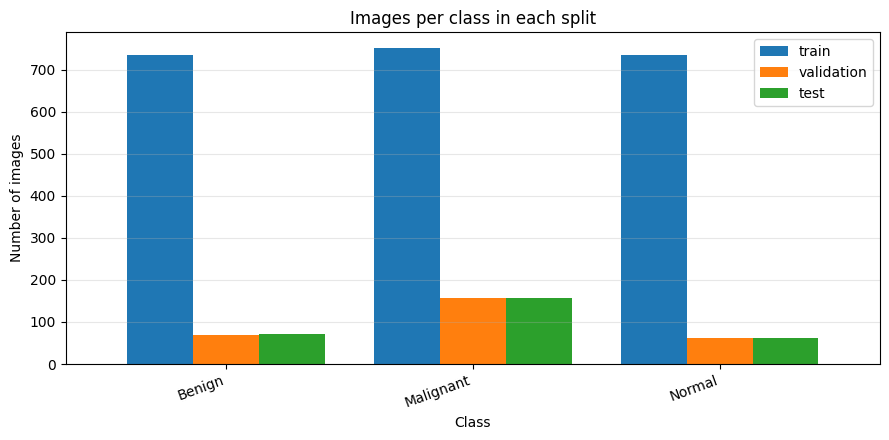

Training imbalance ratio (largest class / smallest class): 1.02
The training data is roughly balanced.
Class weights: {'Benign': 1.007, 'Malignant': 0.986, 'Normal': 1.007} -> USED in training


In [12]:
# ---- Class distribution per split ----
plot_df = counts_df.drop(index="TOTAL")
ax = plot_df.plot(kind="bar", figsize=(9, 4.5), width=0.8)
ax.set_title("Images per class in each split")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Imbalance summary (training split) ----
train_counts = counts_df.loc[CLASS_NAMES, "train"].astype(int)
imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Training imbalance ratio (largest class / smallest class): {imbalance_ratio:.2f}")
if imbalance_ratio >= 1.5:
    print("The training data is noticeably imbalanced: watch macro-F1 and per-class recall, "
          "and consider USE_CLASS_WEIGHTS = True (keep it the same across compared experiments).")
else:
    print("The training data is roughly balanced.")

# ---- Class weights (only used when USE_CLASS_WEIGHTS = True) ----
# weight_c = total / (num_classes * count_c): rare classes get weight > 1.
CLASS_WEIGHTS = {i: float(train_counts.sum() / (NUM_CLASSES * train_counts[c])) for i, c in enumerate(CLASS_NAMES)}
CLASS_WEIGHT_ARG = CLASS_WEIGHTS if USE_CLASS_WEIGHTS else None
print("Class weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in CLASS_WEIGHTS.items()},
      "-> USED in training" if USE_CLASS_WEIGHTS else "-> NOT used (USE_CLASS_WEIGHTS = False)")

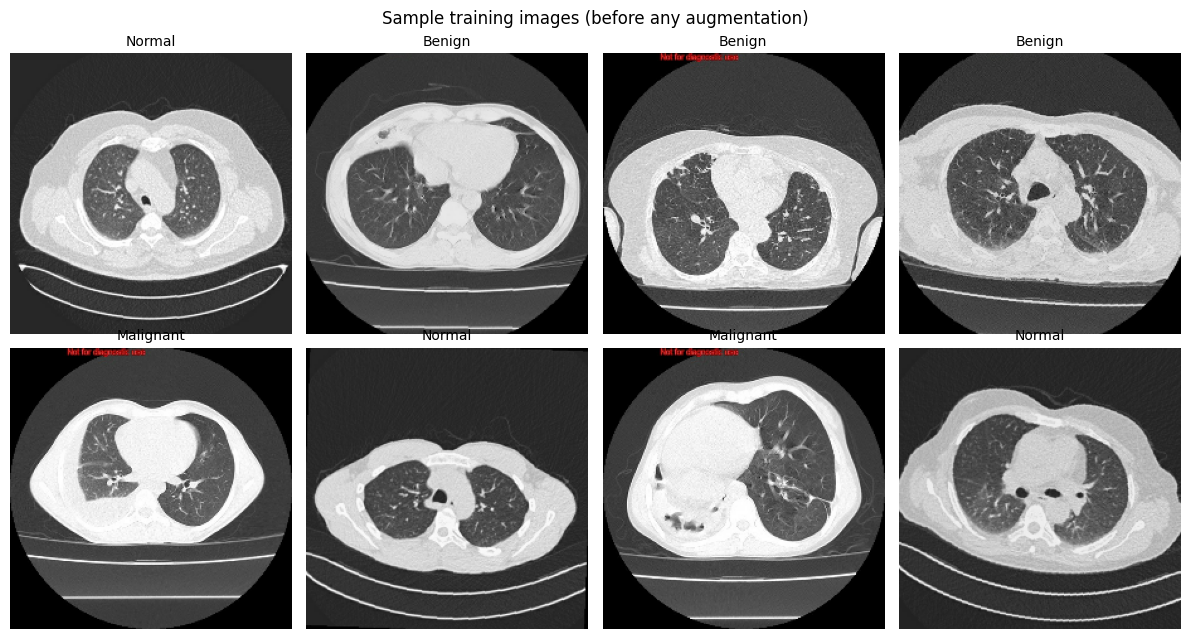

In [13]:
# ---- A few sample images from the training split ----
def to_class_ids(y):
    # Converts one-hot or integer labels to integer class ids.
    y = np.asarray(y)
    return np.argmax(y, axis=1) if y.ndim == 2 else y.astype(int)

sample_images, sample_labels = next(iter(raw_train))
sample_ids = to_class_ids(sample_labels)
n_show = min(8, len(sample_images))
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, img, cid in zip(axes.ravel(), sample_images[:n_show], sample_ids[:n_show]):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(CLASS_NAMES[cid], fontsize=10)
plt.suptitle("Sample training images (before any augmentation)")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Model Architecture Implementation

### 7.1 Which Swin Transformer implementation is actually available?

Do not assume that Keras ships a Swin classifier (for example, `keras_hub.models.SwinTransformerImageClassifier` is **not** something to rely on). The next cell asks the installed libraries what they really contain. Unless it reports a ready-made Swin model **and** you choose to use it, this notebook uses its **own lightweight Swin implementation (Section 7.2)** built only from standard TensorFlow/Keras operations, so it works the same on any Colab setup.

In [14]:
# Ask the installed libraries what Swin-related classes they really provide.
in_keras_apps = [n for n in dir(tf.keras.applications) if "swin" in n.lower()]
print("Swin in tf.keras.applications:", in_keras_apps if in_keras_apps else "none")

if importlib.util.find_spec("keras_hub") is not None:
    import keras_hub
    in_hub = [n for n in dir(keras_hub.models) if "swin" in n.lower()]
    print(f"keras_hub {keras_hub.__version__} Swin-related names:", in_hub if in_hub else "none")
else:
    print("keras_hub is not installed (and is not needed by this notebook).")

print("\nDecision: use the custom Keras Swin implementation below (trained from scratch, no pretrained weights).")

Swin in tf.keras.applications: none
keras_hub 0.26.0 Swin-related names: none

Decision: use the custom Keras Swin implementation below (trained from scratch, no pretrained weights).


### 7.2 Swin Transformer building blocks (custom Keras layers)

**Original vs. proposed.** The code below follows the published Swin design (Liu et al., 2021): patch embedding → stages of (shifted) window-attention blocks → patch merging between stages. It is a compact re-implementation written for this notebook, **trained from scratch**, and not validated against the official weights, so `SwinBaseline` should be read as *"Swin-Tiny-style hyperparameters in this implementation"*.

**Your proposed version** differs only through `SWIN_CONFIG` (and the shared head/loss settings) unless you edit the components. Where each of your six components lives:

| # | Component | Where |
|---|---|---|
| 1 | Patch Embedding | `patch_embedding()` |
| 2 | Window-based Multi-Head Self-Attention | `WindowAttention` layer, used with `shift_size = 0` |
| 3 | Shifted Window Attention | `ShiftedWindowAttention` layer, used with `shift_size > 0` |
| 4 | MLP block | `mlp_block()` |
| 5 | Patch Merging | `PatchMerging` layer + `patch_merging()` |
| 6 | Classification Head | `classification_head()` (shared by all models) |

**Shapes.** Features are kept as `(batch, height, width, channels)` maps. For a 224×224 image with `patch_size=4`: 56×56 → 28×28 → 14×14 → 7×7 tokens, with channels 96 → 192 → 384 → 768.

In [15]:
# ---------------------------------------------------------------------
# Helper functions (plain NumPy / TensorFlow, no weights)
# ---------------------------------------------------------------------
def window_partition(x, H, W, C, ws):
    # (B, H, W, C) -> (B * num_windows, ws*ws, C): cuts the feature map into non-overlapping windows.
    x = tf.reshape(x, (-1, H // ws, ws, W // ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, ws * ws, C))

def window_reverse(w, H, W, C, ws):
    # (B * num_windows, ws*ws, C) -> (B, H, W, C): puts the windows back together.
    x = tf.reshape(w, (-1, H // ws, W // ws, ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, H, W, C))

def make_relative_index(ws):
    # For every pair of positions inside a window, the index of their relative offset (into the bias table).
    coords = np.stack(np.meshgrid(np.arange(ws), np.arange(ws), indexing="ij"))   # (2, ws, ws)
    coords = coords.reshape(2, -1)                                               # (2, N)
    rel = coords[:, :, None] - coords[:, None, :]                                # (2, N, N)
    rel = rel.transpose(1, 2, 0) + (ws - 1)                                      # shift offsets to start at 0
    rel[:, :, 0] *= 2 * ws - 1
    return rel.sum(-1).reshape(-1).astype("int32")                               # (N*N,)

def make_shift_mask(H, W, ws, shift):
    # After shifting the map, some windows contain tokens that were NOT neighbours in the image.
    # This mask (0 or -100) stops those tokens from attending to each other.
    img = np.zeros((1, H, W, 1), dtype="float32")
    regions = (slice(0, -ws), slice(-ws, -shift), slice(-shift, None))
    k = 0
    for h in regions:
        for w in regions:
            img[:, h, w, :] = k
            k += 1
    win = img.reshape(1, H // ws, ws, W // ws, ws, 1).transpose(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws)
    diff = win[:, None, :] - win[:, :, None]                                     # (num_windows, N, N)
    return np.where(diff != 0, -100.0, 0.0).astype("float32")

print("Swin helper functions defined.")

Swin helper functions defined.


In [16]:
# ---------------------------------------------------------------------
# Custom layers
# ---------------------------------------------------------------------
class DropPath(layers.Layer):
    # Stochastic depth: during training, randomly drops the whole residual branch of each sample.
    def __init__(self, rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.rate = float(rate)

    def call(self, x, training=None):
        if not training or self.rate == 0.0:
            return x
        keep = 1.0 - self.rate
        shape = (tf.shape(x)[0],) + (1,) * (len(x.shape) - 1)    # one random number per sample
        mask = tf.floor(keep + tf.random.uniform(shape, dtype=x.dtype))
        return x / keep * mask

    def get_config(self):
        cfg = super().get_config(); cfg.update({"rate": self.rate}); return cfg


class WindowAttention(layers.Layer):
    # Component 2: multi-head self-attention INSIDE each window.
    # Input: (num_windows_total, N, C) where N = window_size * window_size tokens.
    def __init__(self, dim, num_heads, window_size, qkv_bias=True, use_rel_pos_bias=True,
                 attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.dim, self.num_heads, self.window_size = dim, num_heads, window_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = layers.Dense(dim * 3, use_bias=qkv_bias, name="qkv")     # makes queries, keys, values
        self.proj = layers.Dense(dim, name="proj")                         # mixes the heads back together
        self.attn_drop = layers.Dropout(attn_dropout)
        self.proj_drop = layers.Dropout(proj_dropout)
        self.rel_index = make_relative_index(window_size)

    def build(self, input_shape):
        n = self.window_size ** 2
        if self.use_rel_pos_bias:
            # One learnable number per (relative offset, head).
            self.rel_table = self.add_weight(
                shape=((2 * self.window_size - 1) ** 2, self.num_heads),
                initializer=tf.keras.initializers.TruncatedNormal(stddev=0.02),
                trainable=True, name="rel_pos_bias_table")
        self.qkv.build((None, n, self.dim))
        self.proj.build((None, n, self.dim))
        super().build(input_shape)

    def call(self, x, attn_mask=None, training=None):
        n = self.window_size ** 2
        qkv = self.qkv(x)                                                   # (B_, N, 3C)
        qkv = tf.reshape(qkv, (-1, n, 3, self.num_heads, self.head_dim))
        qkv = tf.transpose(qkv, (2, 0, 3, 1, 4))                            # (3, B_, heads, N, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn = tf.matmul(q * self.scale, k, transpose_b=True)               # (B_, heads, N, N)

        if self.use_rel_pos_bias:
            table = tf.convert_to_tensor(self.rel_table)
            bias = tf.gather(table, self.rel_index)                         # (N*N, heads)
            bias = tf.reshape(bias, (n, n, self.num_heads))
            bias = tf.transpose(bias, (2, 0, 1))                            # (heads, N, N)
            attn = attn + tf.expand_dims(bias, 0)

        if attn_mask is not None:                                           # only used by shifted windows
            n_win = attn_mask.shape[0]
            attn = tf.reshape(attn, (-1, n_win, self.num_heads, n, n))
            attn = attn + tf.cast(attn_mask, attn.dtype)[None, :, None, :, :]
            attn = tf.reshape(attn, (-1, self.num_heads, n, n))

        attn = tf.nn.softmax(attn, axis=-1)
        attn = self.attn_drop(attn, training=training)
        out = tf.matmul(attn, v)                                            # (B_, heads, N, head_dim)
        out = tf.reshape(tf.transpose(out, (0, 2, 1, 3)), (-1, n, self.dim))
        out = self.proj(out)
        return self.proj_drop(out, training=training)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"dim": self.dim, "num_heads": self.num_heads, "window_size": self.window_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class ShiftedWindowAttention(layers.Layer):
    # Component 3: window attention on a feature map, optionally with the cyclic SHIFT.
    #   shift_size = 0  -> regular window attention (W-MSA)
    #   shift_size > 0  -> shifted window attention (SW-MSA): roll the map, attend, roll back.
    # Input and output: (B, H, W, C) with H = W = resolution.
    def __init__(self, resolution, dim, num_heads, window_size, shift_size=0, qkv_bias=True,
                 use_rel_pos_bias=True, attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.resolution, self.dim, self.num_heads = resolution, dim, num_heads
        self.window_size, self.shift_size = window_size, shift_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.attn = WindowAttention(dim, num_heads, window_size, qkv_bias, use_rel_pos_bias,
                                    attn_dropout, proj_dropout, name="window_attention")
        self.shift_mask = make_shift_mask(resolution, resolution, window_size, shift_size) if shift_size > 0 else None

    def build(self, input_shape):
        self.attn.build((None, self.window_size ** 2, self.dim))
        super().build(input_shape)

    def call(self, x, training=None):
        H = W = self.resolution
        s = self.shift_size
        if s > 0:
            x = tf.roll(x, shift=[-s, -s], axis=[1, 2])                      # cyclic shift
        win = window_partition(x, H, W, self.dim, self.window_size)
        mask = tf.constant(self.shift_mask) if self.shift_mask is not None else None
        win = self.attn(win, attn_mask=mask, training=training)
        x = window_reverse(win, H, W, self.dim, self.window_size)
        if s > 0:
            x = tf.roll(x, shift=[s, s], axis=[1, 2])                        # undo the shift
        return x

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"resolution": self.resolution, "dim": self.dim, "num_heads": self.num_heads,
                    "window_size": self.window_size, "shift_size": self.shift_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class PatchMerging(layers.Layer):
    # Component 5 (part 1): group each 2x2 neighbourhood of tokens and stack them along channels.
    # (B, H, W, C) -> (B, H/2, W/2, 4C). A LayerNorm + Dense then reduces 4C -> 2C (see patch_merging()).
    def call(self, x):
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        return tf.concat([x0, x1, x2, x3], axis=-1)

# Register the layers by name (safe to re-run this cell; lets Keras find them when a saved model is loaded).
tf.keras.utils.get_custom_objects().update({
    "DropPath": DropPath, "WindowAttention": WindowAttention,
    "ShiftedWindowAttention": ShiftedWindowAttention, "PatchMerging": PatchMerging,
})
print("Swin custom layers defined.")

Swin custom layers defined.


In [17]:
# ---------------------------------------------------------------------
# Building blocks written as plain functions: tensor in -> tensor out
# ---------------------------------------------------------------------
def patch_embedding(x, cfg):
    # Component 1: cut the image into patch_size x patch_size patches and project each to embed_dim.
    # A Conv2D with kernel = stride = patch_size does exactly that.
    x = layers.Conv2D(cfg["embed_dim"], kernel_size=cfg["patch_size"], strides=cfg["patch_size"],
                      name="patch_embed_conv")(x)
    return layers.LayerNormalization(epsilon=1e-5, name="patch_embed_norm")(x)

def mlp_block(x, dim, cfg, name):
    # Component 4: two Dense layers with a GELU in between.
    hidden = int(dim * cfg["mlp_ratio"])
    x = layers.Dense(hidden, activation="gelu", name=f"{name}_mlp_fc1")(x)
    x = layers.Dropout(cfg["dropout_rate"], name=f"{name}_mlp_drop1")(x)
    x = layers.Dense(dim, name=f"{name}_mlp_fc2")(x)
    return layers.Dropout(cfg["dropout_rate"], name=f"{name}_mlp_drop2")(x)

def swin_block(x, res, dim, heads, cfg, shift, drop_path, name):
    # One Swin block = [LayerNorm -> (shifted) window attention -> residual] + [LayerNorm -> MLP -> residual]
    ws = min(cfg["window_size"], res)                 # if the map is smaller than the window, use one window
    shortcut = x
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm1")(x)
    y = ShiftedWindowAttention(res, dim, heads, ws, shift, cfg["qkv_bias"], cfg["use_relative_position_bias"],
                               cfg["attention_dropout_rate"], cfg["dropout_rate"], name=f"{name}_attn")(y)
    y = DropPath(drop_path, name=f"{name}_droppath1")(y)
    x = layers.Add(name=f"{name}_add1")([shortcut, y])

    shortcut = x
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm2")(x)
    y = mlp_block(y, dim, cfg, name)
    y = DropPath(drop_path, name=f"{name}_droppath2")(y)
    return layers.Add(name=f"{name}_add2")([shortcut, y])

def patch_merging(x, dim, name):
    # Component 5: halve the resolution, double the channels (dim -> 2*dim).
    x = PatchMerging(name=f"{name}_concat")(x)
    x = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm")(x)
    return layers.Dense(2 * dim, use_bias=False, name=f"{name}_reduce")(x)

def classification_head(x, num_classes, head_cfg):
    # Component 6: shared by ALL models. feature map -> pooling -> [hidden layers] -> dropout -> softmax.
    pool = layers.GlobalMaxPooling2D if head_cfg["pooling"] == "max" else layers.GlobalAveragePooling2D
    x = pool(name="head_pool")(x)
    for i, units in enumerate(head_cfg["hidden_units"]):
        x = layers.Dense(units, activation=head_cfg["activation"], name=f"head_hidden{i + 1}")(x)
        x = layers.Dropout(head_cfg["dropout_rate"], name=f"head_hidden{i + 1}_dropout")(x)
    x = layers.Dropout(head_cfg["dropout_rate"], name="head_dropout")(x)
    # softmax output -> the loss functions below use from_logits=False
    return layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)

def check_swin_config(cfg, image_size, label="SWIN_CONFIG"):
    # Catches impossible architectures BEFORE building, with an explanation of what to change.
    keys = ["patch_size", "window_size", "embed_dim", "num_heads", "depths", "mlp_ratio", "dropout_rate",
            "attention_dropout_rate", "drop_path_rate", "qkv_bias", "use_shifted_window", "use_relative_position_bias"]
    missing_keys = [k for k in keys if k not in cfg]
    if missing_keys:
        raise KeyError(f"{label} is missing keys: {missing_keys}")
    if image_size[0] != image_size[1]:
        raise ValueError("The Swin implementation expects a square IMAGE_SIZE, e.g. (224, 224).")
    if len(cfg["depths"]) != len(cfg["num_heads"]):
        raise ValueError(f"{label}: 'depths' and 'num_heads' must have the same length (one entry per stage).")
    if image_size[0] % cfg["patch_size"] != 0:
        raise ValueError(f"{label}: IMAGE_SIZE {image_size[0]} must be divisible by patch_size {cfg['patch_size']}.")
    for key in ("dropout_rate", "attention_dropout_rate", "drop_path_rate"):
        if not 0.0 <= cfg[key] < 1.0:
            raise ValueError(f"{label}: {key} must be in [0, 1).")
    res, ws = image_size[0] // cfg["patch_size"], cfg["window_size"]
    for s, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        dim = cfg["embed_dim"] * 2 ** s
        if dim % heads != 0:
            raise ValueError(f"{label}: stage {s + 1} has {dim} channels, not divisible by {heads} heads. "
                             "Change embed_dim or num_heads.")
        if res > ws and res % ws != 0:
            raise ValueError(f"{label}: stage {s + 1} token grid is {res}x{res}, not divisible by window_size {ws}. "
                             "Change window_size, patch_size or IMAGE_SIZE.")
        if s < len(cfg["depths"]) - 1:
            if res % 2 != 0:
                raise ValueError(f"{label}: stage {s + 1} grid {res}x{res} cannot be halved by patch merging.")
            res //= 2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_VAR  = [0.229 ** 2, 0.224 ** 2, 0.225 ** 2]

def build_swin(cfg, head_cfg, num_classes, image_size, name="Swin"):
    # Assembles the full Swin classifier from the components above.
    check_swin_config(cfg, image_size, label=name)
    inputs = layers.Input(shape=(*image_size, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)                       # 0-255 -> 0-1
    x = layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_VAR, name="normalize")(x)
    x = patch_embedding(x, cfg)

    res, dim = image_size[0] // cfg["patch_size"], cfg["embed_dim"]
    total_blocks = sum(cfg["depths"])
    drop_rates = np.linspace(0.0, cfg["drop_path_rate"], total_blocks)             # grows with depth
    block_id = 0
    for stage, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        for i in range(depth):
            # Odd blocks use the shifted window (unless disabled or the map fits in one window).
            shifted = cfg["use_shifted_window"] and (i % 2 == 1) and res > cfg["window_size"]
            shift = cfg["window_size"] // 2 if shifted else 0
            x = swin_block(x, res, dim, heads, cfg, shift, float(drop_rates[block_id]), f"stage{stage + 1}_block{i + 1}")
            block_id += 1
        if stage < len(cfg["depths"]) - 1:
            x = patch_merging(x, dim, f"stage{stage + 1}_merge")
            res, dim = res // 2, dim * 2

    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    outputs = classification_head(x, num_classes, head_cfg)
    return tf.keras.Model(inputs, outputs, name=name)

print("Swin building blocks and build_swin() defined.")

Swin building blocks and build_swin() defined.


### 7.3 Self-tests for the Swin code

Quick checks that catch bugs and API incompatibilities **before** you spend hours training:

1. Cutting a feature map into windows and putting it back gives the original map.
2. The shifted-window mask has the right shape and only contains 0 / −100.
3. A tiny Swin does a forward pass, outputs valid probabilities, and takes one training step (so gradients reach all weights).
4. Stochastic depth is off at inference time (two predictions on the same input are identical).

In [18]:
def run_swin_self_tests():
    # 1) window partition + reverse must give back the original tensor
    x = tf.random.normal((2, 14, 14, 8))
    back = window_reverse(window_partition(x, 14, 14, 8, 7), 14, 14, 8, 7)
    np.testing.assert_allclose(x.numpy(), back.numpy(), atol=1e-6)

    # 2) relative index and shift mask
    idx = make_relative_index(7)
    assert idx.shape == (49 * 49,) and idx.min() == 0 and idx.max() == (2 * 7 - 1) ** 2 - 1
    mask = make_shift_mask(14, 14, 7, 3)
    assert mask.shape == (4, 49, 49), mask.shape
    assert set(np.unique(mask).tolist()) <= {0.0, -100.0}
    assert (mask[0] == 0).all(), "the first window is not split by the shift and must be unmasked"

    # 3) tiny Swin: forward pass + one training step
    tiny = {"patch_size": 4, "window_size": 7, "embed_dim": 16, "num_heads": [2, 4], "depths": [2, 2],
            "mlp_ratio": 2.0, "dropout_rate": 0.1, "attention_dropout_rate": 0.1, "drop_path_rate": 0.1,
            "qkv_bias": True, "use_shifted_window": True, "use_relative_position_bias": True}
    head = {"pooling": "avg", "hidden_units": [8], "activation": "gelu", "dropout_rate": 0.1}
    model = build_swin(tiny, head, 3, (56, 56), name="tiny_swin")
    xb = np.random.uniform(0, 255, (4, 56, 56, 3)).astype("float32")
    p1 = model.predict(xb, verbose=0)
    assert p1.shape == (4, 3), p1.shape
    np.testing.assert_allclose(p1.sum(axis=1), 1.0, atol=1e-4)
    np.testing.assert_allclose(p1, model.predict(xb, verbose=0), atol=1e-5)       # 4) deterministic at inference
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    loss = model.train_on_batch(xb, np.array([0, 1, 2, 0]))
    assert np.isfinite(np.asarray(loss)).all(), "training step produced a non-finite loss"

    # 5) ablation switches must also build
    for flag in ("use_shifted_window", "use_relative_position_bias"):
        variant = dict(tiny, **{flag: False})
        build_swin(variant, head, 3, (56, 56), name="tiny_variant")

    tf.keras.backend.clear_session(); gc.collect()
    print("All Swin self-tests passed.")

if RUN_SELF_TESTS:
    run_swin_self_tests()
else:
    print("Self-tests skipped (RUN_SELF_TESTS = False).")

All Swin self-tests passed.


## 8. Loss Function and Optimizer Configuration

These helpers turn the **names in the configuration cell** into Keras objects.

**Label / output compatibility (important):**

* Every model ends with a **softmax** layer, so every loss uses `from_logits=False`.
* **Categorical** losses need **one-hot** labels. **Sparse** loss needs **integer** labels. Section 5 already loads labels in the right format; the accuracy metric below is chosen to match.
* Label smoothing needs one-hot labels, which is why Keras has no label smoothing for the sparse loss.

**What each loss does:**

| Loss | Idea |
|---|---|
| Categorical CE / Sparse categorical CE | Identical maths, different label format. Penalises low probability on the true class. |
| CE + label smoothing | Softens the target, which reduces over-confidence. Sometimes improves generalisation and calibration; accuracy gains are not guaranteed. |
| Categorical focal | Down-weights examples the model already gets right, so training focuses on hard ones. Sometimes used with class imbalance; it can also hurt. |

Weight decay is passed to the optimizer when `WEIGHT_DECAY > 0` (Keras applies it as decoupled weight decay).

In [19]:
def get_loss():
    # Returns the Keras loss object that matches LOSS_FUNCTION_NAME.
    name = LOSS_FUNCTION_NAME
    if name == "sparse_categorical_crossentropy":
        return tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
    if name in ("categorical_crossentropy", "categorical_crossentropy_label_smoothing"):
        return tf.keras.losses.CategoricalCrossentropy(from_logits=False, label_smoothing=LABEL_SMOOTHING)
    if name == "categorical_focal_crossentropy":
        if not hasattr(tf.keras.losses, "CategoricalFocalCrossentropy"):
            raise RuntimeError("This TensorFlow/Keras version has no CategoricalFocalCrossentropy. "
                               "Choose another loss or upgrade TensorFlow.")
        return tf.keras.losses.CategoricalFocalCrossentropy(
            alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA, from_logits=False, label_smoothing=LABEL_SMOOTHING)
    raise ValueError(f"Unknown loss: {name}")

def get_metrics():
    # Accuracy metric whose label format matches the loss (names stay "accuracy" / "val_accuracy").
    if LABEL_MODE == "int":
        return [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    return [tf.keras.metrics.CategoricalAccuracy(name="accuracy")]

def get_optimizer():
    # A NEW optimizer object is needed for every model.
    name = OPTIMIZER_NAME.lower()
    wd = WEIGHT_DECAY if WEIGHT_DECAY > 0 else None
    if name == "adam":
        return tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, weight_decay=wd)
    if name == "adamw":
        return tf.keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    if name == "sgd":
        return tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=SGD_MOMENTUM, weight_decay=wd)
    if name == "rmsprop":
        return tf.keras.optimizers.RMSprop(learning_rate=LEARNING_RATE, weight_decay=wd)
    raise ValueError(f"Unknown optimizer: {OPTIMIZER_NAME}")

def compile_model(model):
    model.compile(optimizer=get_optimizer(), loss=get_loss(), metrics=get_metrics())
    return model

# Fail early if the chosen loss/optimizer cannot be created in this TensorFlow version.
_ = get_loss(); _ = get_optimizer()
print("Loss     :", type(get_loss()).__name__, "| label_smoothing =", LABEL_SMOOTHING)
print("Optimizer:", type(get_optimizer()).__name__, f"| lr = {LEARNING_RATE} | weight_decay = {WEIGHT_DECAY}")
print("Labels   :", LABEL_MODE)

Loss     : CategoricalCrossentropy | label_smoothing = 0.0
Optimizer: Adam | lr = 0.001 | weight_decay = 0.0
Labels   : categorical


## 9. Model Building and Summary

`build_model(model_name)` returns a ready-to-compile Keras model for any name in `MODEL_NAMES`.

* **CNNs:** ImageNet-pretrained backbone (`include_top=False`) → *the shared head from Section 7*. The model-specific preprocessing function is the first layer, so the data pipeline stays identical for every model.
* **Swin:** `SwinBaseline` uses `SWIN_BASELINE_CONFIG`, `SwinTransformer` uses your `SWIN_CONFIG`. Both use the same head and the same normalisation.

After building, each model is tested on a **real batch** to confirm the output shape matches `(batch, NUM_CLASSES)` and the outputs are valid probabilities.

In [20]:
from tensorflow.keras.applications import ResNet50, EfficientNetB0, MobileNetV2, DenseNet121
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_pre
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_pre
from tensorflow.keras.applications.densenet import preprocess_input as densenet_pre

# name -> (Keras constructor, the matching preprocessing function)
CNN_REGISTRY = {
    "ResNet50":       (ResNet50, resnet_pre),
    "EfficientNetB0": (EfficientNetB0, effnet_pre),
    "MobileNetV2":    (MobileNetV2, mobilenet_pre),
    "DenseNet121":    (DenseNet121, densenet_pre),
}
SWIN_CONFIGS = {"SwinBaseline": SWIN_BASELINE_CONFIG, "SwinTransformer": SWIN_CONFIG}

def swin_cfg_for(model_name):
    # Returns the Swin config used by a model name (None for CNNs).
    return SWIN_CONFIGS.get(model_name)

def build_cnn(model_name):
    constructor, preprocess = CNN_REGISTRY[model_name]
    backbone = constructor(weights="imagenet" if USE_PRETRAINED else None,
                           include_top=False, input_shape=(*IMAGE_SIZE, 3))
    backbone.trainable = not FREEZE_BACKBONE
    inputs = layers.Input(shape=(*IMAGE_SIZE, 3), name="image")
    x = layers.Lambda(preprocess, name="model_preprocessing")(inputs)       # raw 0-255 -> what this network expects
    # A frozen pretrained backbone must run in inference mode so BatchNorm statistics are not updated.
    x = backbone(x, training=False) if (USE_PRETRAINED and FREEZE_BACKBONE) else backbone(x)
    outputs = classification_head(x, NUM_CLASSES, HEAD_CONFIG)
    return tf.keras.Model(inputs, outputs, name=model_name)

def build_model(model_name):
    # One entry point for every supported model.
    if model_name in CNN_REGISTRY:
        return build_cnn(model_name)
    if model_name in SWIN_CONFIGS:
        return build_swin(SWIN_CONFIGS[model_name], HEAD_CONFIG, NUM_CLASSES, IMAGE_SIZE, name=model_name)
    raise ValueError(f"Unknown model '{model_name}'. Valid names: {VALID_MODELS}")

def count_params(model):
    total = model.count_params()
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    return total, trainable

# ---- Build each selected model once to check it and print a summary ----
smoke_images, _ = next(iter(raw_val))
for name in MODEL_NAMES:
    tf.keras.backend.clear_session(); gc.collect()
    model = build_model(name)
    total, trainable = count_params(model)
    out = model.predict_on_batch(smoke_images)
    assert out.shape == (smoke_images.shape[0], NUM_CLASSES), f"{name}: unexpected output shape {out.shape}"
    assert np.allclose(np.asarray(out).sum(axis=1), 1.0, atol=1e-3), f"{name}: outputs are not probabilities"
    print(f"{name:16s} total params {total / 1e6:7.2f} M | trainable {trainable / 1e6:7.2f} M | output {out.shape}")
    if SHOW_FULL_SUMMARY:
        model.summary(line_length=110)
    del model

tf.keras.backend.clear_session(); gc.collect()

SwinBaseline     total params   27.52 M | trainable   27.52 M | output (16, 3)
SwinTransformer  total params   27.52 M | trainable   27.52 M | output (16, 3)


0

In [21]:
# ---- Show the Swin structure(s) in a compact table ----
rows = []
for name in MODEL_NAMES:
    cfg = swin_cfg_for(name)
    if cfg is None:
        continue
    res, dim = IMAGE_SIZE[0] // cfg["patch_size"], cfg["embed_dim"]
    for s, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        ws = min(cfg["window_size"], res)
        rows.append({"Model": name, "Stage": s + 1, "Token grid": f"{res}x{res}", "Channels": dim, "Heads": heads,
                     "Blocks": depth, "Window": ws,
                     "Shifted blocks": (depth // 2) if (cfg["use_shifted_window"] and res > cfg["window_size"]) else 0})
        res, dim = res // 2, dim * 2
if rows:
    display(pd.DataFrame(rows))
else:
    print("No Swin model selected in MODEL_NAMES.")

,Model,Stage,Token grid,Channels,Heads,Blocks,Window,Shifted blocks
0,SwinBaseline,1,56x56,96,3,2,7,1
1,SwinBaseline,2,28x28,192,6,2,7,1
2,SwinBaseline,3,14x14,384,12,6,7,3
3,SwinBaseline,4,7x7,768,24,2,7,0
4,SwinTransformer,1,56x56,96,3,2,7,1
5,SwinTransformer,2,28x28,192,6,2,7,1
6,SwinTransformer,3,14x14,384,12,6,7,3
7,SwinTransformer,4,7x7,768,24,2,7,0


## 10. Model Training

Models are trained **one after another** (never in parallel) with identical settings. For each model the loop:

1. clears the TensorFlow session and resets the seed (every model starts under the same conditions, and GPU memory is freed);
2. builds and compiles the model;
3. trains with **EarlyStopping**, **ModelCheckpoint** and **ReduceLROnPlateau**, all monitoring **validation loss**;
4. **saves the best weights** (lowest validation loss) to `CHECKPOINTS_DIR` and **reloads them** after training;
5. records the history and the training time.

The **test set is never touched here.** Model selection uses validation loss only.

If a model runs out of GPU memory, the error is printed with advice (lower `BATCH_SIZE`), that model is skipped, and training continues with the next one. Any other error stops the notebook so it is never hidden.

In [22]:
def make_callbacks(model_name):
    # All three callbacks watch validation loss. Checkpoints go to CHECKPOINTS_DIR.
    ckpt_path = str(Path(CHECKPOINTS_DIR) / f"{RUN_ID}_{model_name}_best.weights.h5")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", mode="min",
                                           save_best_only=True, save_weights_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOPPING_PATIENCE,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=REDUCE_LR_FACTOR,
                                             patience=REDUCE_LR_PATIENCE, min_lr=MIN_LEARNING_RATE, verbose=1),
        tf.keras.callbacks.CSVLogger(str(HISTORIES_DIR / f"{model_name}_epoch_log.csv")),
    ]
    return callbacks, ckpt_path

def train_one_model(model_name):
    # Builds, trains and returns (model with best weights, history dict, seconds, checkpoint path).
    tf.keras.backend.clear_session(); gc.collect()      # free memory from the previous model
    set_all_seeds(SEED)                                 # same starting conditions for every model
    model = compile_model(build_model(model_name))
    callbacks, ckpt_path = make_callbacks(model_name)
    total, trainable = count_params(model)
    print(f"\n{'=' * 78}\nTraining {model_name}  |  params {total / 1e6:.2f} M (trainable {trainable / 1e6:.2f} M)\n{'=' * 78}")

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks,
                        class_weight=CLASS_WEIGHT_ARG, verbose=2)
    seconds = time.time() - start

    # Explicitly restore the best (lowest validation loss) weights from disk.
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f"Best-weights checkpoint was not written: {ckpt_path}")
    model.load_weights(ckpt_path)
    return model, history.history, seconds, ckpt_path

trained_models, trained_histories, training_seconds, checkpoint_paths = {}, {}, {}, {}
train_info, failed_models = {}, {}

for model_name in MODEL_NAMES:
    try:
        model, hist, secs, ckpt = train_one_model(model_name)
    except tf.errors.ResourceExhaustedError as e:
        failed_models[model_name] = "out of GPU memory"
        print(f"\nERROR: {model_name} ran out of GPU memory. Lower BATCH_SIZE (for example 16 or 8) in the "
              f"configuration cell, or use a smaller Swin (fewer depths / smaller embed_dim).\nDetails: {str(e)[:300]}")
        tf.keras.backend.clear_session(); gc.collect()
        continue

    trained_models[model_name] = model
    trained_histories[model_name] = hist
    training_seconds[model_name] = secs
    checkpoint_paths[model_name] = ckpt

    best_epoch = int(np.argmin(hist["val_loss"])) + 1
    train_info[model_name] = {
        "epochs_run": len(hist["loss"]), "best_epoch": best_epoch,
        "best_val_loss": float(np.min(hist["val_loss"])),
        "best_val_accuracy": float(np.max(hist["val_accuracy"])),
        "val_accuracy_at_best_loss": float(hist["val_accuracy"][best_epoch - 1]),
    }
    pd.DataFrame(hist).to_csv(HISTORIES_DIR / f"{model_name}_history.csv", index_label="epoch")
    print(f"\n{model_name}: finished in {secs / 60:.1f} min | epochs run {len(hist['loss'])} | "
          f"best epoch {best_epoch} | best val loss {train_info[model_name]['best_val_loss']:.4f}")

if failed_models:
    print("\nModels that could NOT be trained:", failed_models)
if not trained_models:
    raise RuntimeError("No model was trained successfully. See the errors above.")


Training SwinBaseline  |  params 27.52 M (trainable 27.52 M)
Epoch 1/10

Epoch 1: val_loss improved from None to 1.03291, saving model to /content/drive/MyDrive/Lung_Cancer_Checkpoints/20261125_102008_SwinBaseline_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Lung_Cancer_Checkpoints/20261125_102008_SwinBaseline_best.weights.h5
139/139 - 450s - 3s/step - accuracy: 0.3134 - loss: 1.8752 - val_accuracy: 0.5433 - val_loss: 1.0329 - learning_rate: 0.0010
Epoch 2/10

Epoch 2: val_loss did not improve from 1.03291
139/139 - 51s - 369ms/step - accuracy: 0.3206 - loss: 1.2751 - val_accuracy: 0.2145 - val_loss: 1.4205 - learning_rate: 0.0010
Epoch 3/10

Epoch 3: val_loss did not improve from 1.03291
139/139 - 49s - 355ms/step - accuracy: 0.3368 - loss: 1.2056 - val_accuracy: 0.2422 - val_loss: 1.1035 - learning_rate: 0.0010
Epoch 4/10

Epoch 4: val_loss improved from 1.03291 to 1.02412, saving model to /content/drive/MyDrive/Lung_Cancer_Checkpoints/20261125_102008_Sw

## 11. Model Evaluation

Every model is evaluated on **the same validation and test sets**, using the **best-validation-loss weights** restored in Section 10.

**Metrics** (multi-class, so precision/recall/F1 are averaged across classes):

* **Accuracy** – fraction of correct predictions.
* **Macro precision / recall / F1** – unweighted mean over classes, so every class counts equally (important for imbalanced data). **Macro-F1 is the headline metric here.**
* **Weighted F1** – mean over classes weighted by class size.
* **ROC-AUC (one-vs-rest, macro)** – computed from the predicted probabilities.
* **Confusion matrix** and **classification report** (per-class precision / recall / F1).

**Experimental integrity:** the **validation** metrics are what you use to *choose* settings. The **test** metrics are for the final report; do not tune hyperparameters by looking at them. If you do, the test set quietly becomes a second validation set and your reported numbers become optimistic.

In [23]:
def predict_with_labels(model, ds):
    # One pass over a (non-shuffled) dataset: returns predicted probabilities and true class ids,
    # so predictions and labels are guaranteed to be aligned.
    probs, ys = [], []
    for x, y in ds:
        probs.append(model.predict_on_batch(x))
        ys.append(to_class_ids(y.numpy()))
    return np.concatenate(probs).astype("float64"), np.concatenate(ys)

def roc_auc_macro(y_true, probs):
    # One-vs-rest macro ROC-AUC. Returns NaN (and says why) if it cannot be computed.
    p = probs / probs.sum(axis=1, keepdims=True)         # make rows sum to exactly 1
    try:
        if NUM_CLASSES == 2:
            return float(roc_auc_score(y_true, p[:, 1]))
        return float(roc_auc_score(y_true, p, multi_class="ovr", average="macro", labels=list(range(NUM_CLASSES))))
    except ValueError as e:
        print("ROC-AUC could not be computed:", e)
        return float("nan")

def calc_metrics(y_true, probs):
    pred = probs.argmax(axis=1)
    return {
        "accuracy":        accuracy_score(y_true, pred) * 100,
        "precision_macro": precision_score(y_true, pred, average="macro", zero_division=0) * 100,
        "recall_macro":    recall_score(y_true, pred, average="macro", zero_division=0) * 100,
        "f1_macro":        f1_score(y_true, pred, average="macro", zero_division=0) * 100,
        "f1_weighted":     f1_score(y_true, pred, average="weighted", zero_division=0) * 100,
        "roc_auc_macro":   roc_auc_macro(y_true, probs),
    }

eval_results, reference_val_labels, reference_test_labels = {}, None, None

for name, model in trained_models.items():
    val_probs, y_val = predict_with_labels(model, val_ds)
    test_probs, y_test = predict_with_labels(model, test_ds)

    # Sanity check: all models must see identical labels in identical order.
    if reference_val_labels is None:
        reference_val_labels, reference_test_labels = y_val, y_test
    assert np.array_equal(y_val, reference_val_labels) and np.array_equal(y_test, reference_test_labels), \
        "Label order differs between models: evaluation would not be comparable."

    # Sanity check: restored weights should reproduce the best validation loss from training.
    val_eval = model.evaluate(val_ds, verbose=0, return_dict=True)
    gap = abs(val_eval["loss"] - train_info[name]["best_val_loss"])
    print(f"{name:16s} restored val loss {val_eval['loss']:.4f} vs best logged {train_info[name]['best_val_loss']:.4f}"
          + ("" if gap < 1e-2 else "   <-- differs: check that the best weights were restored"))

    eval_results[name] = {
        "val": calc_metrics(y_val, val_probs), "test": calc_metrics(y_test, test_probs),
        "val_loss": float(val_eval["loss"]), "val_probs": val_probs, "test_probs": test_probs,
        "y_val": y_val, "y_test": y_test,
        "cm": confusion_matrix(y_test, test_probs.argmax(axis=1), labels=list(range(NUM_CLASSES))),
        "report": classification_report(y_test, test_probs.argmax(axis=1), labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, output_dict=True, zero_division=0),
    }

    # Save predictions for later analysis (for example McNemar tests between models).
    pred_df = pd.DataFrame(test_probs, columns=[f"prob_{c}" for c in CLASS_NAMES])
    pred_df.insert(0, "true_class", [CLASS_NAMES[i] for i in y_test])
    pred_df.insert(1, "pred_class", [CLASS_NAMES[i] for i in test_probs.argmax(axis=1)])
    pred_df.to_csv(PREDICTIONS_DIR / f"{name}_test_predictions.csv", index=False)
    pd.DataFrame(eval_results[name]["report"]).T.to_csv(METRICS_DIR / f"{name}_classification_report.csv")

SwinBaseline     restored val loss 1.0241 vs best logged 1.0241
SwinTransformer  restored val loss 0.9974 vs best logged 0.9974


In [24]:
# ---- Comparison table (one row per model) ----
rows = []
for name, r in eval_results.items():
    total, trainable = count_params(trained_models[name])
    rows.append({
        "Model": name,
        "Val Loss": r["val_loss"], "Val Accuracy (%)": r["val"]["accuracy"], "Val Macro F1 (%)": r["val"]["f1_macro"],
        "Test Accuracy (%)": r["test"]["accuracy"], "Test Precision macro (%)": r["test"]["precision_macro"],
        "Test Recall macro (%)": r["test"]["recall_macro"], "Test Macro F1 (%)": r["test"]["f1_macro"],
        "Test Weighted F1 (%)": r["test"]["f1_weighted"], "Test ROC-AUC (macro)": r["test"]["roc_auc_macro"],
        "Params (M)": total / 1e6, "Training Time (min)": training_seconds[name] / 60,
        "Epochs Run": train_info[name]["epochs_run"], "Best Epoch": train_info[name]["best_epoch"],
    })

# Sorted by VALIDATION macro-F1: the validation set is what you select models with.
comparison_df = pd.DataFrame(rows).set_index("Model").sort_values("Val Macro F1 (%)", ascending=False)
display(comparison_df.round(4))
comparison_df.to_csv(METRICS_DIR / "model_comparison.csv")

# ---- Detailed per-model reports (test set) ----
for name, r in eval_results.items():
    print(f"\n{'-' * 70}\n{name}: classification report on the TEST set\n{'-' * 70}")
    print(classification_report(r["y_test"], r["test_probs"].argmax(axis=1), labels=list(range(NUM_CLASSES)),
                                target_names=CLASS_NAMES, digits=4, zero_division=0))

,Val Loss,Val Accuracy (%),Val Macro F1 (%),Test Accuracy (%),Test Precision macro (%),Test Recall macro (%),Test Macro F1 (%),Test Weighted F1 (%),Test ROC-AUC (macro),Params (M),Training Time (min),Epochs Run,Best Epoch
Model,,,,,,,,,,,,,
SwinBaseline,1.0241,54.3253,23.4679,54.1096,18.0365,33.3333,23.4074,37.997,0.5038,27.5217,12.7526,7,4
SwinTransformer,0.9974,54.3253,23.4679,54.1096,18.0365,33.3333,23.4074,37.997,0.6455,27.5217,13.3354,10,8



----------------------------------------------------------------------
SwinBaseline: classification report on the TEST set
----------------------------------------------------------------------
              precision    recall  f1-score   support

      Benign     0.0000    0.0000    0.0000        71
   Malignant     0.5411    1.0000    0.7022       158
      Normal     0.0000    0.0000    0.0000        63

    accuracy                         0.5411       292
   macro avg     0.1804    0.3333    0.2341       292
weighted avg     0.2928    0.5411    0.3800       292


----------------------------------------------------------------------
SwinTransformer: classification report on the TEST set
----------------------------------------------------------------------
              precision    recall  f1-score   support

      Benign     0.0000    0.0000    0.0000        71
   Malignant     0.5411    1.0000    0.7022       158
      Normal     0.0000    0.0000    0.0000        63

    accu

## 12. Performance Visualization

All graphs are shown here and saved to `GRAPHS_DIR` on Google Drive.

How to read the learning curves:

* **Training accuracy keeps rising while validation accuracy flattens or falls**, and validation loss rises: *overfitting*.
* **Both curves stay low**: *underfitting* (model too small, learning rate too low, or too much regularisation).
* **Large epoch-to-epoch jumps in validation loss**: the validation set may be small; treat small differences between models with caution.

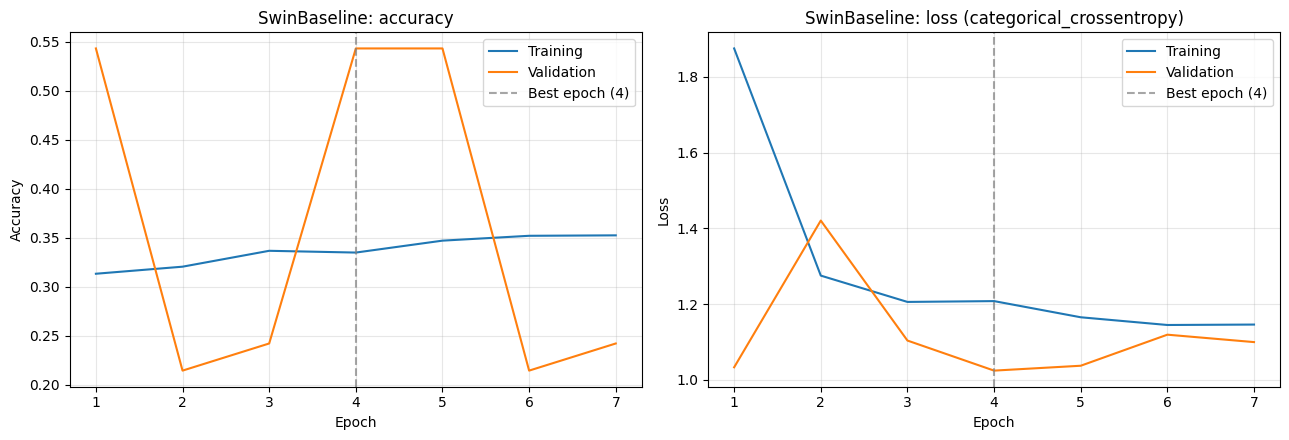

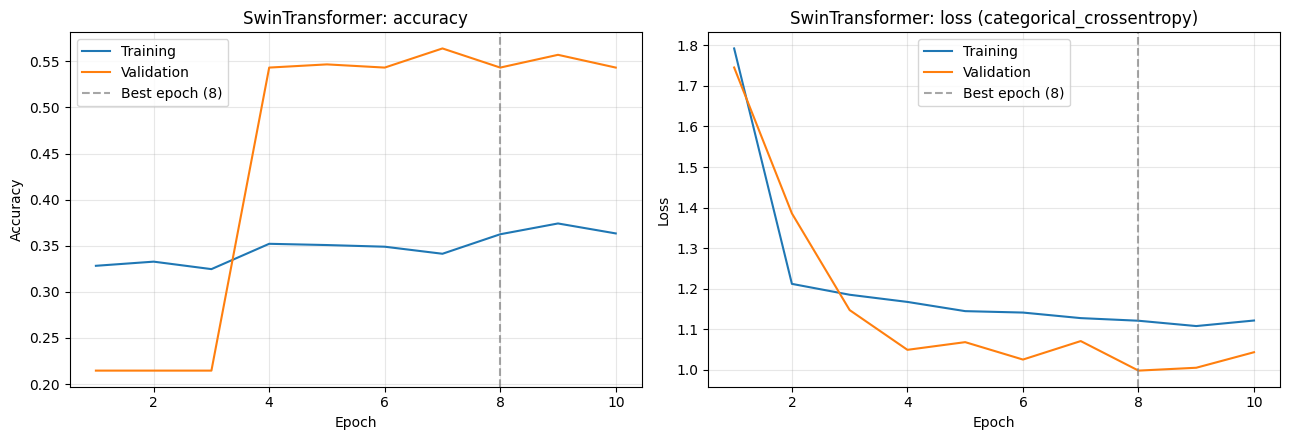

In [25]:
# ---- 1 & 2: training vs validation accuracy and loss (one figure per model) ----
for name, hist in trained_histories.items():
    epochs = range(1, len(hist["loss"]) + 1)
    best_ep = train_info[name]["best_epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(epochs, hist["accuracy"], label="Training")
    axes[0].plot(epochs, hist["val_accuracy"], label="Validation")
    axes[0].set(title=f"{name}: accuracy", xlabel="Epoch", ylabel="Accuracy")

    axes[1].plot(epochs, hist["loss"], label="Training")
    axes[1].plot(epochs, hist["val_loss"], label="Validation")
    axes[1].set(title=f"{name}: loss ({LOSS_FUNCTION_NAME})", xlabel="Epoch", ylabel="Loss")

    for ax in axes:
        ax.axvline(best_ep, color="gray", linestyle="--", alpha=0.7, label=f"Best epoch ({best_ep})")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout()
    plt.savefig(GRAPHS_DIR / f"{name}_training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

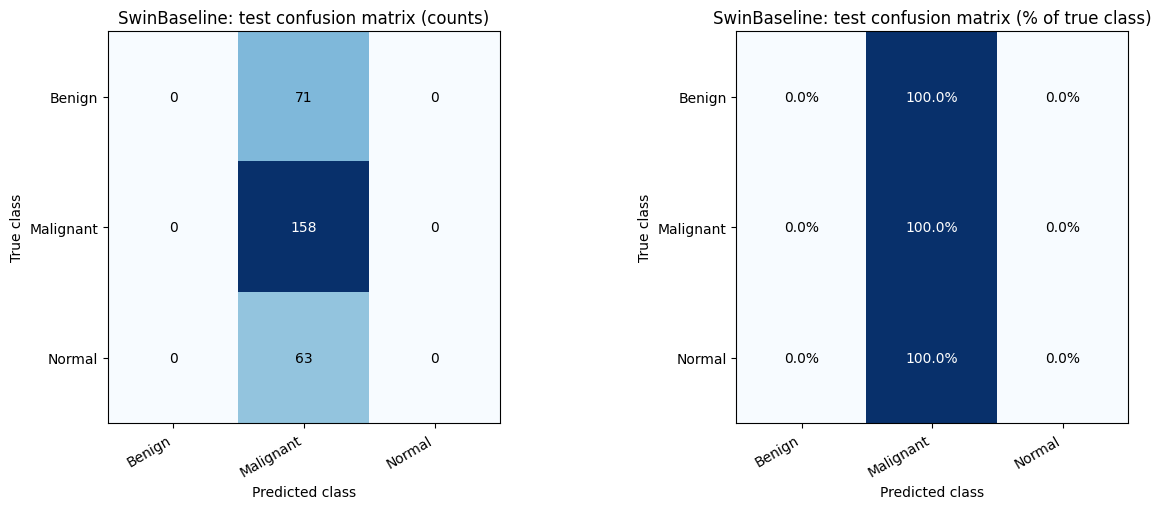

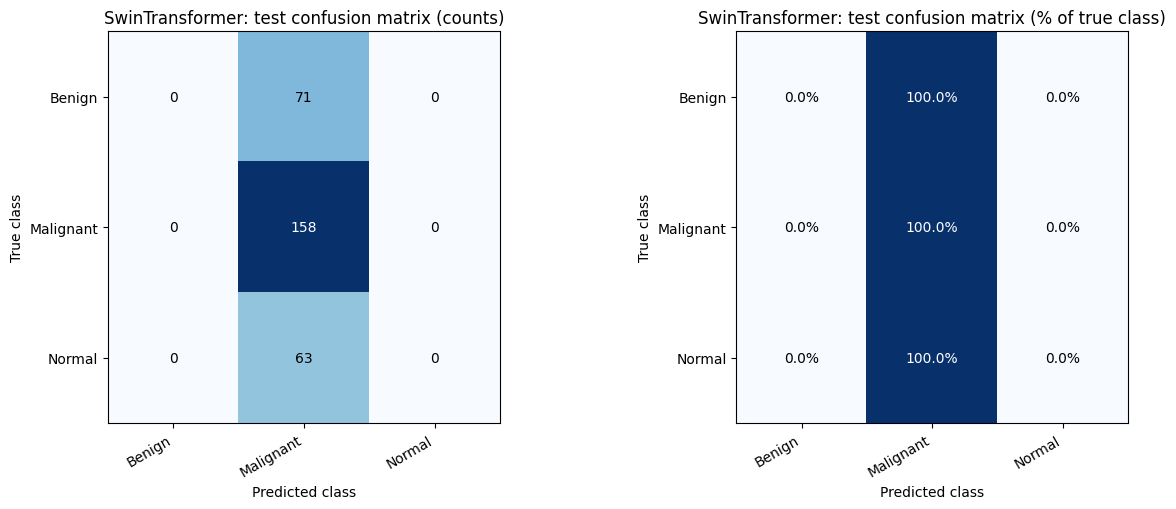

In [26]:
# ---- 3: confusion matrix per model (counts and row-normalised) ----
def draw_confusion(ax, cm, title, normalize):
    data = cm / cm.sum(axis=1, keepdims=True).clip(min=1) if normalize else cm
    im = ax.imshow(data, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set(title=title, xlabel="Predicted class", ylabel="True class",
           xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
           xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    top = data.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            text = f"{data[i, j] * 100:.1f}%" if normalize else str(int(data[i, j]))
            ax.text(j, i, text, ha="center", va="center", color="white" if data[i, j] > top else "black")
    return im

for name, r in eval_results.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    draw_confusion(axes[0], r["cm"], f"{name}: test confusion matrix (counts)", normalize=False)
    draw_confusion(axes[1], r["cm"], f"{name}: test confusion matrix (% of true class)", normalize=True)
    plt.tight_layout()
    plt.savefig(GRAPHS_DIR / f"{name}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

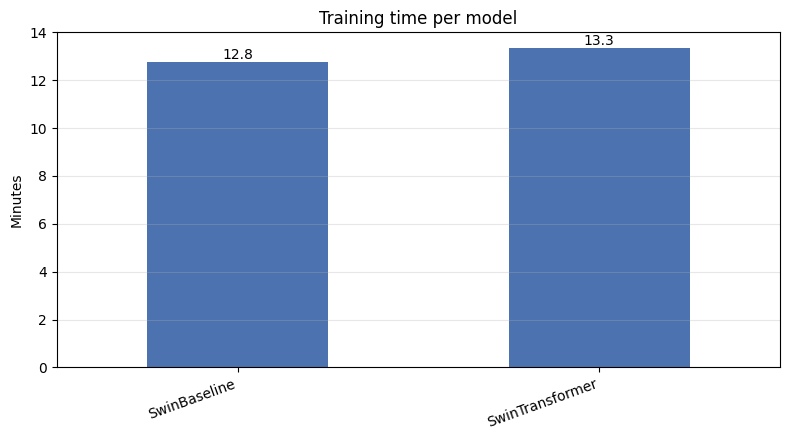

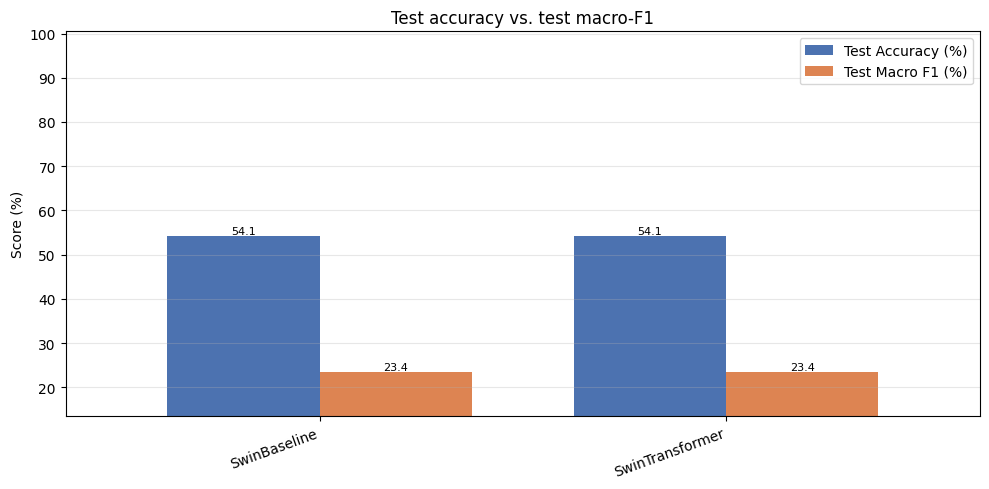

Note: the y-axis of the second chart does not start at 0, to make small differences visible. Small differences from a single run are often just random variation.


In [27]:
# ---- 4: comparison table (already displayed) is saved; 5: training time; 6: accuracy and macro-F1 ----
fig, ax = plt.subplots(figsize=(8, 4.5))
comparison_df["Training Time (min)"].plot(kind="bar", ax=ax, color="#4C72B0")
ax.set(title="Training time per model", ylabel="Minutes", xlabel="")
ax.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(GRAPHS_DIR / "training_time_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
comparison_df[["Test Accuracy (%)", "Test Macro F1 (%)"]].plot(kind="bar", ax=ax, width=0.75, color=["#4C72B0", "#DD8452"])
lowest = float(comparison_df[["Test Accuracy (%)", "Test Macro F1 (%)"]].min().min())
ax.set(title="Test accuracy vs. test macro-F1", ylabel="Score (%)", xlabel="", ylim=(max(0, lowest - 10), 100.5))
ax.grid(axis="y", alpha=0.3)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(GRAPHS_DIR / "accuracy_macro_f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Note: the y-axis of the second chart does not start at 0, to make small differences visible. "
      "Small differences from a single run are often just random variation.")

## 13. Experiment Comparison

Every notebook run **appends one row per model** to a single CSV file (`experiment_log.csv` in `RESULTS_DIR`). Change a setting in Section 3, run again, and the new rows are added below the old ones.

Columns include the experiment ID, model, loss, learning rate, optimizer, batch size, epochs, the important Swin parameters, best validation accuracy / loss, test accuracy, test macro-F1 and training time.

**Reading the log honestly:**

* Choose the best configuration by **validation** macro-F1 / validation loss (the `Val ...` columns).
* Use the **test** columns only to report the final chosen configuration.
* A difference between two configurations from **one seed** may be noise. Repeat with several seeds (change `SEED`, keep everything else) and compare mean ± standard deviation (the last cell of this section does that for you).

In [28]:
EXPERIMENT_LOG_PATH = Path(RESULTS_DIR) / "experiment_log.csv"

def make_log_row(name):
    info, r, sc = train_info[name], eval_results[name], swin_cfg_for(name)
    total, trainable = count_params(trained_models[name])
    row = {
        "Experiment ID": f"{RUN_ID}_{name}", "Experiment Name": EXPERIMENT_NAME, "Notes": EXPERIMENT_NOTES,
        "Run ID": RUN_ID, "Date": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "Model": name, "Loss Function": LOSS_FUNCTION_NAME, "Label Smoothing": LABEL_SMOOTHING,
        "Focal Gamma": FOCAL_GAMMA if LOSS_FUNCTION_NAME == "categorical_focal_crossentropy" else "",
        "Class Weights": USE_CLASS_WEIGHTS, "Optimizer": OPTIMIZER_NAME, "Learning Rate": LEARNING_RATE,
        "Weight Decay": WEIGHT_DECAY, "Batch Size": BATCH_SIZE, "Epochs (max)": EPOCHS,
        "Epochs Run": info["epochs_run"], "Best Epoch": info["best_epoch"], "Seed": SEED,
        "Image Size": f"{IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}", "Augmentation": USE_AUGMENTATION,
        "Head Hidden Units": str(HEAD_CONFIG["hidden_units"]), "Head Dropout": HEAD_CONFIG["dropout_rate"],
        "Params (M)": round(total / 1e6, 3),
        # Swin-specific columns (empty for CNN models)
        "Patch Size": sc["patch_size"] if sc else "", "Window Size": sc["window_size"] if sc else "",
        "Embed Dim": sc["embed_dim"] if sc else "", "Num Heads": str(sc["num_heads"]) if sc else "",
        "Depths": str(sc["depths"]) if sc else "", "MLP Ratio": sc["mlp_ratio"] if sc else "",
        "Swin Dropout": sc["dropout_rate"] if sc else "", "Attention Dropout": sc["attention_dropout_rate"] if sc else "",
        "Drop Path": sc["drop_path_rate"] if sc else "", "Shifted Window": sc["use_shifted_window"] if sc else "",
        "Rel Pos Bias": sc["use_relative_position_bias"] if sc else "",
        # Results
        "Best Val Accuracy (%)": round(info["best_val_accuracy"] * 100, 3), "Best Val Loss": round(info["best_val_loss"], 5),
        "Val Macro F1 (%)": round(r["val"]["f1_macro"], 3),
        "Test Accuracy (%)": round(r["test"]["accuracy"], 3), "Test Macro F1 (%)": round(r["test"]["f1_macro"], 3),
        "Training Time (s)": round(training_seconds[name], 1),
    }
    return row

new_rows = pd.DataFrame([make_log_row(n) for n in eval_results])

# Append to the existing log (if any). Using concat means new columns in a later version never break old logs.
if EXPERIMENT_LOG_PATH.exists():
    try:
        old = pd.read_csv(EXPERIMENT_LOG_PATH)
    except Exception as e:
        raise RuntimeError(f"Could not read the existing log {EXPERIMENT_LOG_PATH}: {e}. "
                           "Rename or fix the file so earlier results are not lost.") from e
    experiment_log = pd.concat([old, new_rows], ignore_index=True)
else:
    experiment_log = new_rows
experiment_log.to_csv(EXPERIMENT_LOG_PATH, index=False)
new_rows.to_csv(METRICS_DIR / "this_run_experiment_rows.csv", index=False)
print(f"Log updated: {EXPERIMENT_LOG_PATH}  ({len(experiment_log)} rows in total, {len(new_rows)} new)")

# Full log, best validation macro-F1 first.
show_cols = ["Experiment ID", "Experiment Name", "Model", "Loss Function", "Label Smoothing", "Optimizer", "Learning Rate",
             "Window Size", "Embed Dim", "Depths", "Drop Path", "Seed", "Best Val Accuracy (%)", "Best Val Loss",
             "Val Macro F1 (%)", "Test Accuracy (%)", "Test Macro F1 (%)", "Training Time (s)"]
display(experiment_log.sort_values("Val Macro F1 (%)", ascending=False)[show_cols].reset_index(drop=True))

Log updated: /content/drive/MyDrive/Lung_Cancer_Experiment_Results/experiment_log.csv  (4 rows in total, 2 new)


,Experiment ID,Experiment Name,Model,Loss Function,Label Smoothing,Optimizer,Learning Rate,Window Size,Embed Dim,Depths,Drop Path,Seed,Best Val Accuracy (%),Best Val Loss,Val Macro F1 (%),Test Accuracy (%),Test Macro F1 (%),Training Time (s)
0,20261125_102008_SwinBaseline,swin_ce_run1,SwinBaseline,categorical_crossentropy,0.0,adam,0.001,7.0,96.0,"[2, 2, 6, 2]",0.2,42.0,54.325,1.02412,23.468,54.11,23.407,765.2
1,20261125_102008_SwinTransformer,swin_ce_run1,SwinTransformer,categorical_crossentropy,0.0,adam,0.001,7.0,96.0,"[2, 2, 6, 2]",0.1,42.0,56.401,0.99735,23.468,54.11,23.407,800.1
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
# ---- Baseline vs proposed Swin in THIS run (same data, same recipe, same seed) ----
if {"SwinBaseline", "SwinTransformer"} <= set(eval_results):
    b, p = eval_results["SwinBaseline"], eval_results["SwinTransformer"]
    cmp_df = pd.DataFrame({
        "SwinBaseline": [b["val_loss"], b["val"]["f1_macro"], b["test"]["accuracy"], b["test"]["f1_macro"]],
        "SwinTransformer (proposed)": [p["val_loss"], p["val"]["f1_macro"], p["test"]["accuracy"], p["test"]["f1_macro"]],
    }, index=["Val Loss", "Val Macro F1 (%)", "Test Accuracy (%)", "Test Macro F1 (%)"])
    cmp_df["Difference (proposed - baseline)"] = cmp_df.iloc[:, 1] - cmp_df.iloc[:, 0]
    display(cmp_df.round(4))
    print("CAUTION: this is ONE seed on ONE split. A small difference does not show that the proposed model is better.")
    print("Repeat with several seeds (Section 15) and compare mean +/- std before drawing any conclusion.")
else:
    print("Train both 'SwinBaseline' and 'SwinTransformer' in the same run to see the baseline-vs-proposed table.")

# ---- Summary across ALL logged runs: mean +/- std over seeds ----
group_cols = ["Experiment Name", "Model", "Loss Function", "Label Smoothing", "Learning Rate"]
summary = (experiment_log.groupby(group_cols, dropna=False)
           .agg(Runs=("Seed", "nunique"),
                Val_MacroF1_mean=("Val Macro F1 (%)", "mean"), Val_MacroF1_std=("Val Macro F1 (%)", "std"),
                Test_Acc_mean=("Test Accuracy (%)", "mean"), Test_Acc_std=("Test Accuracy (%)", "std"),
                Test_MacroF1_mean=("Test Macro F1 (%)", "mean"), Test_MacroF1_std=("Test Macro F1 (%)", "std"))
           .reset_index().sort_values("Val_MacroF1_mean", ascending=False))
print("\nSummary over all logged runs (std is NaN until a configuration has been run with 2+ seeds):")
display(summary.round(3))
summary.to_csv(Path(RESULTS_DIR) / "experiment_summary_by_config.csv", index=False)

,SwinBaseline,SwinTransformer (proposed),Difference (proposed - baseline)
Val Loss,1.0241,0.9974,-0.0268
Val Macro F1 (%),23.4679,23.4679,0.0000
Test Accuracy (%),54.1096,54.1096,0.0000
Test Macro F1 (%),23.4074,23.4074,0.0000


CAUTION: this is ONE seed on ONE split. A small difference does not show that the proposed model is better.
Repeat with several seeds (Section 15) and compare mean +/- std before drawing any conclusion.

Summary over all logged runs (std is NaN until a configuration has been run with 2+ seeds):


,Experiment Name,Model,Loss Function,Label Smoothing,Learning Rate,Runs,Val_MacroF1_mean,Val_MacroF1_std,Test_Acc_mean,Test_Acc_std,Test_MacroF1_mean,Test_MacroF1_std
0,swin_ce_run1,SwinBaseline,categorical_crossentropy,0.0,0.001,1,23.468,NaN,54.11,NaN,23.407,NaN
1,swin_ce_run1,SwinTransformer,categorical_crossentropy,0.0,0.001,1,23.468,NaN,54.11,NaN,23.407,NaN
2,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


## 14. Save Results and Final Models

Saved to Google Drive:

* **Model weights** (`*.weights.h5`) in `MODELS_DIR`: restored best-validation-loss weights. To use a model later, rebuild it with `build_model(name)` and call `model.load_weights(path)`. This is the most robust way to store Swin and the CNN models, because custom layers and `Lambda` preprocessing layers can complicate loading full-model files.
* A **full model file** (`*.keras`) is also attempted. If saving fails, a warning explains why (the weights file is still saved).
* The **run configuration** (`config.json`) with every setting, class names, dataset counts and library versions, so the run can be reproduced.
* Metrics, predictions, histories and graphs were already written to `RUN_DIR` in earlier sections.

In [30]:
saved_files = {}
for name, model in trained_models.items():
    weights_path = Path(MODELS_DIR) / f"{RUN_ID}_{name}_best.weights.h5"
    model.save_weights(str(weights_path))
    saved_files[name] = {"weights": str(weights_path)}

    # Try to also save the full model. Report (do not hide) any problem.
    full_path = Path(MODELS_DIR) / f"{RUN_ID}_{name}.keras"
    try:
        model.save(str(full_path))
        saved_files[name]["full_model"] = str(full_path)
    except Exception as e:
        print(f"WARNING: could not save the full .keras file for {name}: {type(e).__name__}: {str(e)[:200]}")
        print(f"         The weights file was saved: {weights_path}")

# ---- Run configuration (everything needed to reproduce the run) ----
run_config = {
    "run_id": RUN_ID, "experiment_name": EXPERIMENT_NAME, "notes": EXPERIMENT_NOTES,
    "models_trained": list(trained_models), "models_failed": failed_models,
    "dataset_root": str(DATASET_ROOT), "split_folders": {k: str(v) for k, v in SPLIT_DIRS.items()},
    "class_names_in_label_order": CLASS_NAMES,
    "image_counts": counts_df.to_dict(), "image_size": list(IMAGE_SIZE), "batch_size": BATCH_SIZE,
    "epochs_max": EPOCHS, "learning_rate": LEARNING_RATE, "optimizer": OPTIMIZER_NAME, "weight_decay": WEIGHT_DECAY,
    "seed": SEED, "deterministic_ops": DETERMINISTIC_OPS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE, "reduce_lr_patience": REDUCE_LR_PATIENCE,
    "reduce_lr_factor": REDUCE_LR_FACTOR, "min_learning_rate": MIN_LEARNING_RATE,
    "loss_function": LOSS_FUNCTION_NAME, "label_smoothing": LABEL_SMOOTHING, "focal_gamma": FOCAL_GAMMA,
    "focal_alpha": FOCAL_ALPHA, "label_mode": LABEL_MODE, "use_class_weights": USE_CLASS_WEIGHTS,
    "use_augmentation": USE_AUGMENTATION, "augmentation_config": AUGMENTATION_CONFIG,
    "use_pretrained_cnn": USE_PRETRAINED, "freeze_cnn_backbone": FREEZE_BACKBONE,
    "head_config": HEAD_CONFIG, "swin_baseline_config": SWIN_BASELINE_CONFIG, "swin_config": SWIN_CONFIG,
    "model_selection_metric": "validation loss (checkpoint) / validation macro-F1 (ranking)",
    "test_set_used_for_selection": False,
    "checkpoints": checkpoint_paths, "saved_files": saved_files,
    "versions": {"python": platform.python_version(), "tensorflow": tf.__version__, "keras": tf.keras.__version__,
                 "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    "gpus": [g.name for g in gpus],
}
with open(RUN_DIR / "config.json", "w") as f:
    json.dump(run_config, f, indent=2, default=str)
with open(Path(MODELS_DIR) / f"{RUN_ID}_class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

print("Saved model files:")
for n, files in saved_files.items():
    print(f"  {n}: {files}")
print("\nRun folder     :", RUN_DIR)
print("Experiment log :", EXPERIMENT_LOG_PATH)

Saved model files:
  SwinBaseline: {'weights': '/content/drive/MyDrive/Lung_Cancer_Trained_Models/20261125_102008_SwinBaseline_best.weights.h5', 'full_model': '/content/drive/MyDrive/Lung_Cancer_Trained_Models/20261125_102008_SwinBaseline.keras'}
  SwinTransformer: {'weights': '/content/drive/MyDrive/Lung_Cancer_Trained_Models/20261125_102008_SwinTransformer_best.weights.h5', 'full_model': '/content/drive/MyDrive/Lung_Cancer_Trained_Models/20261125_102008_SwinTransformer.keras'}

Run folder     : /content/drive/MyDrive/Lung_Cancer_Experiment_Results/run_20261125_102008
Experiment log : /content/drive/MyDrive/Lung_Cancer_Experiment_Results/experiment_log.csv


**How to load a saved model later (new notebook or session):**

```python
# 1) re-run Sections 2, 3, 7, 8 and 9 (so the same config and build_model() exist)
model = build_model("SwinTransformer")          # same name and same SWIN_CONFIG as when it was trained
model.load_weights("/content/drive/MyDrive/Lung_Cancer_Trained_Models/<RUN_ID>_SwinTransformer_best.weights.h5")
```

## 15. Future Experimentation Guide

### 15.1 How to make a fair baseline-vs-proposed comparison

1. **Same data.** One fixed train / validation / test split for every run (this notebook reuses your folders and never re-splits). Check Section 4 reports no duplicate leakage.
2. **Same recipe.** Same image size, batch size, optimizer, learning rate, epochs, early stopping, augmentation and class-weight setting for the baseline and the proposed model. Only the thing you are testing may differ.
3. **Change one factor at a time (ablation).** Example plan, using the same seeds each time:

   | Run | Model | Loss | What it tells you |
   |---|---|---|---|
   | A | `SwinBaseline` | categorical CE | reference |
   | B | `SwinBaseline` | CE + label smoothing 0.1 | effect of the **loss** alone |
   | C | `SwinTransformer` | categorical CE | effect of **your architecture change** alone |
   | D | `SwinTransformer` | CE + label smoothing 0.1 | the combination |

   Comparing only A with D would not tell you which change helped.
4. **Several seeds.** Repeat every run with at least 3 to 5 seeds (change `SEED`; keep everything else). Section 13 reports mean ± std per configuration. If the difference between two configurations is smaller than the seed-to-seed spread, you cannot claim one is better.
5. **Same tuning effort.** Give the baseline the same hyperparameter search budget as the proposed model; otherwise you are comparing a tuned model to an untuned one.
6. **Select on validation, report on test.** Pick settings with validation loss / validation macro-F1. Look at the test set only for the final chosen configuration. Never tune on test.
7. **Report macro-F1 and per-class recall**, not only accuracy, especially if the classes are imbalanced. For medical data, per-class recall (sensitivity) of the disease classes matters.
8. **Be explicit about limits:** Swin here is trained from scratch while the CNNs are ImageNet-pretrained; results are for one dataset; the architecture is an implementation of a published design with your modifications, not a proven new method. For a paper, add statistical tests (for example McNemar's test on the saved prediction CSVs) and an external or held-out dataset if you can.

### 15.2 Where to change things

| I want to change... | Edit |
|---|---|
| Loss, label smoothing, focal parameters | Section 3 (`LOSS_FUNCTION_NAME`, `LABEL_SMOOTHING`, `FOCAL_*`); add a new loss in `get_loss()` (Section 8) and in `LOSS_LABEL_MODE` (Section 3) |
| Optimizer, learning rate, weight decay | Section 3 (`OPTIMIZER_NAME`, `LEARNING_RATE`, `WEIGHT_DECAY`) |
| Heads, window size, embedding dimension, depths | `SWIN_CONFIG` in Section 3 |
| Remove shifted windows / relative position bias (ablation) | `SWIN_CONFIG["use_shifted_window"]` / `["use_relative_position_bias"]` = `False` |
| Classification head (hidden layers, dropout, pooling) | `HEAD_CONFIG` in Section 3 (shared by all models, so comparisons stay fair) |
| Attention mechanism | `WindowAttention.call()` in Section 7 (for example a different bias, scaling or a cosine attention) |
| Feature extraction / MLP | `mlp_block()` and `swin_block()` in Section 7 |
| Patch embedding / merging | `patch_embedding()`, `patch_merging()`, `PatchMerging` in Section 7 |

After editing Section 7 code, **re-run the self-test cell** (Section 7.3) before training.

### 15.3 Ideas worth testing (none is guaranteed to help)

* Label smoothing in {0.05, 0.1, 0.15}; focal loss with gamma in {1, 2}; class weights on/off (an imbalanced dataset only).
* A smaller Swin for a small dataset: `depths=[2,2,2,2]`, `embed_dim=64` or `[1,1,3,1]`, because the default Swin-Tiny has about 27 M parameters and is trained from scratch.
* `OPTIMIZER_NAME="adamw"` with `WEIGHT_DECAY` 0.01 to 0.05 and `LEARNING_RATE` 1e-3 or 5e-4 (typical for transformers).
* `USE_AUGMENTATION=True` for the Swin models (transformers trained from scratch usually need stronger regularisation or more data).
* Window size and patch size ablations (remember the divisibility rule; Section 7 tells you if a combination is impossible).
* `FREEZE_BACKBONE=False` with `LEARNING_RATE=1e-5` to fine-tune the CNNs.

### 15.4 Common problems

| Message | What to do |
|---|---|
| `DATASET_ROOT does not exist` | Mount Drive (Section 2) and correct the path in Section 3 |
| `Could not find the 'val' folder` | Add your folder name to `SPLIT_FOLDER_NAMES` |
| Out of GPU memory | Lower `BATCH_SIZE`, use a smaller Swin, or restart the runtime |
| `... not divisible by window_size` | Change `window_size`, `patch_size` or `IMAGE_SIZE` (Section 7 message says which stage) |
| Sparse loss with label smoothing error | Use `categorical_crossentropy` instead (needs one-hot labels, which the notebook loads for you) |
| Swin accuracy far below the CNNs | Expected at first: Swin starts from random weights. Try a smaller Swin, AdamW, augmentation, more epochs |